In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import csv
import seaborn as sns
import numpy as np
from scipy.stats import chi2_contingency
from scipy import stats

* # Data Reading and Copying

In [2]:
# using the python reader to go through it so it is accessible
with open('T2_B25-census-3.csv', 'r') as file:
    csv_reader = csv.reader(file, delimiter=',')
    # print(csv_reader)
    for  i in csv_reader:
        print(i)

['House Number', 'Street', 'First Name', 'Surname', 'Age', 'Relationship to Head of House', 'Marital Status', 'Gender', 'Occupation', 'Infirmity', 'Religion']
['1', 'Inverness Mission', 'Darren', 'Kaur', '79', 'Head', 'Widowed', 'Male', 'Retired Surveyor, building control', 'None', 'Christian']
['2', 'Inverness Mission', 'Dean', 'Hughes', '66', 'Head', 'Widowed', 'Male', 'Financial trader', 'None', 'Christian']
['3', 'Inverness Mission', 'Andrew', 'Freeman', '19', 'Head', 'Single', 'Male', 'University Student', 'None', 'None']
['4', 'Inverness Mission', 'Sally', 'Ward', '40', 'Head', 'Single', 'Female', 'Chief Marketing Officer', 'None', 'Christian']
['4', 'Inverness Mission', 'Brandon', 'Thorpe', '38', 'Partner', 'Single', 'Male', 'Secondary school teacher', 'None', 'Christian']
['4', 'Inverness Mission', 'Glenn', 'Ward', '5', 'Son', 'NA', 'Male', 'Student', 'None', 'NA']
['5', 'Inverness Mission', 'Lesley', 'Gill', '74', 'Head', 'Widowed', 'Female', 'Retired Dancer', 'None', 'Christi

In [3]:
# creating a copy of this csv file so as not to tamper with the original csv file
with open('T2_B25-census-3-copy.csv', 'w', newline="") as file2:
    csv_writer = csv.writer(file2)

    with open('T2_B25-census-3.csv', 'r') as file:
        csv_reader = csv.reader(file, delimiter=',')

        for i in csv_reader:
            csv_writer.writerow(i)
print(csv_writer)
    
    # csv_writer.writerow(csv_reader)

* Creating a copy of the csv file is impportant so as to retain the previous file and compare the differences and to have a backup for when
data is lost unintentionally.

In [4]:
# reading through the created copy
with open('T2_B25-census-3-copy.csv', 'r') as file:
    csv_reader = csv.reader(file, delimiter=',')
    for i in csv_reader:
        print(i)

['House Number', 'Street', 'First Name', 'Surname', 'Age', 'Relationship to Head of House', 'Marital Status', 'Gender', 'Occupation', 'Infirmity', 'Religion']
['1', 'Inverness Mission', 'Darren', 'Kaur', '79', 'Head', 'Widowed', 'Male', 'Retired Surveyor, building control', 'None', 'Christian']
['2', 'Inverness Mission', 'Dean', 'Hughes', '66', 'Head', 'Widowed', 'Male', 'Financial trader', 'None', 'Christian']
['3', 'Inverness Mission', 'Andrew', 'Freeman', '19', 'Head', 'Single', 'Male', 'University Student', 'None', 'None']
['4', 'Inverness Mission', 'Sally', 'Ward', '40', 'Head', 'Single', 'Female', 'Chief Marketing Officer', 'None', 'Christian']
['4', 'Inverness Mission', 'Brandon', 'Thorpe', '38', 'Partner', 'Single', 'Male', 'Secondary school teacher', 'None', 'Christian']
['4', 'Inverness Mission', 'Glenn', 'Ward', '5', 'Son', 'NA', 'Male', 'Student', 'None', 'NA']
['5', 'Inverness Mission', 'Lesley', 'Gill', '74', 'Head', 'Widowed', 'Female', 'Retired Dancer', 'None', 'Christi

* # Data Cleaning Process

* Cleaning data is very important, it gives room for accuracy, it allows the data  to all have filled columns, it takes out outliers, lies
and ensures data is fully prepared and ready for further analysis

In [5]:
# creating a dataframe with pandas
df = pd.read_csv('T2_B25-census-3-copy.csv')
df

,House Number,Street,First Name,Surname,Age,Relationship to Head of House,Marital Status,Gender,Occupation,Infirmity,Religion
0,1,Inverness Mission,Darren,Kaur,79,Head,Widowed,Male,"Retired Surveyor, building control",NaN,Christian
1,2,Inverness Mission,Dean,Hughes,66,Head,Widowed,Male,Financial trader,NaN,Christian
2,3,Inverness Mission,Andrew,Freeman,19,Head,Single,Male,University Student,NaN,NaN
3,4,Inverness Mission,Sally,Ward,40,Head,Single,Female,Chief Marketing Officer,NaN,Christian
4,4,Inverness Mission,Brandon,Thorpe,38,Partner,Single,Male,Secondary school teacher,NaN,Christian
...,...,...,...,...,...,...,...,...,...,...,...
8781,1,Ferguson Villa,Lewis,Parkin-Webb,16,Grandson,NaN,Male,Student,NaN,NaN
8782,1,Ferguson Villa,Adrian,Parkin-Webb,16,Grandson,NaN,Male,Student,NaN,NaN
8783,1,Ferguson Villa,Caroline,Parkin-Webb,13,Adopted Granddaughter,NaN,Female,Student,NaN,NaN
8784,1,Ferguson Villa,Justin,Parkin-Webb,10,Grandson,NaN,Male,Student,NaN,NaN


In [6]:
# reading through the dataframe to see the types on each column
df.dtypes

House Number                     object
Street                           object
First Name                       object
Surname                          object
Age                              object
Relationship to Head of House    object
Marital Status                   object
Gender                           object
Occupation                       object
Infirmity                        object
Religion                         object
dtype: object

In [7]:
# reading through the dataframe to get more information like types. number of null values in each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8786 entries, 0 to 8785
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   House Number                   8786 non-null   object
 1   Street                         8786 non-null   object
 2   First Name                     8786 non-null   object
 3   Surname                        8786 non-null   object
 4   Age                            8786 non-null   object
 5   Relationship to Head of House  8223 non-null   object
 6   Marital Status                 6646 non-null   object
 7   Gender                         8786 non-null   object
 8   Occupation                     8786 non-null   object
 9   Infirmity                      77 non-null     object
 10  Religion                       3693 non-null   object
dtypes: object(11)
memory usage: 755.2+ KB


In [8]:
# checking for the number of null values in each column
df.isna().sum()

House Number                        0
Street                              0
First Name                          0
Surname                             0
Age                                 0
Relationship to Head of House     563
Marital Status                   2140
Gender                              0
Occupation                          0
Infirmity                        8709
Religion                         5093
dtype: int64

In [9]:
# setting to option to allow for viewing all unique values and row
pd.set_option('display.max_rows', None)

* # House Number Cleaning

* The house number is a very useful column because it not only tells the area and street a person lives in, but the exact house a person
lives in and this can signify further relationships between persons with the same house number.

In [12]:
# viewing distinct values of the dataframe
df['House Number'].unique()

array(['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12',
       '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23',
       '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34',
       '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45',
       '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56',
       '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67',
       '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78',
       '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89',
       '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100',
       '101', '102', '103', '104', '105', '106', '107', '108', '109',
       '110', '111', '112', '113', '114', '115', '116', '117', '118',
       '119', '120', '121', '122', '123', '124', '125', '126', '127',
       '128', '129', '130', '131', '132', '133', '134', '135', '136',
       '137', '138', '139', '140', '141', '142', '143', '144', '1

In [13]:
# begining with the first column, the house number, checking for null values
df['House Number'].isnull().sum()

np.int64(0)

In [14]:
# using value_counts to check for the number of rows on each distict value in the house number
df['House Number'].value_counts()

House Number
1      357
2      264
4      261
12     253
3      245
8      236
10     235
6      232
5      227
11     220
9      216
7      208
14     205
13     194
15     178
17     169
16     163
19     148
21     147
22     145
18     139
20     134
23     128
24     126
25     115
27     115
26     114
28     100
31      94
32      91
30      90
29      86
33      83
45      79
38      73
35      71
40      70
36      69
37      68
44      67
34      66
39      66
43      64
42      63
41      61
47      59
46      53
49      49
48      45
51      45
50      44
52      37
54      24
55      22
57      22
56      21
53      21
58      21
63      20
77      20
107     20
78      19
113     18
66      18
133     18
118     17
129     17
140     17
149     17
145     17
162     17
164     17
92      17
106     16
97      16
88      16
75      16
60      16
165     16
91      16
120     15
141     15
156     15
104     15
93      15
117     15
72      15
85      15
83      15
86      

In [15]:
# using the count to check number of house number rows
df['House Number'].count()

np.int64(8786)

In [16]:
# checking the number of One in the house number column
count = (df['House Number']== 'One').sum()
print(count)

1


In [17]:
# converting the One to 1 as house number is meant to be numeric
df['House Number'] = df['House Number'].replace('One', '1')

In [18]:
# converting house number to numeric values instead of the current string
df['House Number'] = pd.to_numeric(df['House Number'], errors='coerce')

In [19]:
# rechecking the unique values in the house number after cleaning
df['House Number'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

In [20]:
# rechecking for any null values after converting to numerics as all nulls, empty strings, string values will move to nans
df['House Number'].isnull().sum()

np.int64(0)

In [21]:
# reccheking the unique values in house number
df['House Number'].unique()

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
       105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
       118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
       131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
       144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
       157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
       170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 18

# Column 2: Street Cleaning

In [22]:
# going through the rows in Street
df['Street']

0           Inverness Mission
1           Inverness Mission
2           Inverness Mission
3           Inverness Mission
4           Inverness Mission
5           Inverness Mission
6           Inverness Mission
7           Inverness Mission
8           Inverness Mission
9           Inverness Mission
10          Inverness Mission
11          Inverness Mission
12          Inverness Mission
13          Inverness Mission
14          Inverness Mission
15          Inverness Mission
16          Inverness Mission
17          Inverness Mission
18          Inverness Mission
19          Inverness Mission
20          Inverness Mission
21          Inverness Mission
22          Inverness Mission
23          Inverness Mission
24          Inverness Mission
25          Inverness Mission
26          Inverness Mission
27          Inverness Mission
28          Inverness Mission
29          Inverness Mission
30          Inverness Mission
31          Inverness Mission
32          Inverness Mission
33        

In [23]:
# checking for distinct values in Street
df['Street'].unique()

array(['Inverness Mission', 'Gold Road', 'Whitehall Street', 'Allen Ford',
       'Druid Prairie', 'Racoon Road', 'Reid Club', 'Minster Creek',
       'York Lane', 'Wakefieldbait Avenue', 'Wales Center',
       'Wright Forest', 'Belle Lane', 'Whitehalllink Avenue',
       'Evans Lane', 'Magpiepush Lane', 'Daisy Gateway', 'Polaris Avenue',
       'Gwent Avenue', 'Quinn Road', 'Hughes Street', 'St.Matthew Lane',
       'Yates Shoal', 'Goldfish Street', 'Foxglove Avenue',
       'Goldfish Divide', 'Orchard Road', 'Hearthawk Street',
       'Goldfishpick Avenue', 'Mason Loaf', 'Jones Junction',
       'Cancer Ramp', 'Hunt Lock', 'Glasgow Drive', 'Harvey Village',
       'Prince Avenue', 'Breakfast Road', 'Barry Avenue', 'Hove Lane',
       'Alberthook Lane', 'Tamarisk Prairie', 'Wright Cove',
       'Strawberrydike Street', 'June Road', 'Hardy Grove',
       'Albion Drive', 'Scotland Lane', 'Thomas Drive', 'Hussain Loaf',
       'Akhtar Drive', 'Bibi Coves', 'Watts Lane', 'Spencer Point',


In [24]:
#  checking for the number of null values
df['Street'].isnull().sum()

np.int64(0)

In [25]:
#  checking for empty strings in street
(df['Street'] == "").sum()

np.int64(0)

* # First Name Cleaning

In [26]:
# this shows only the First Name details
df['First Name']

0            Darren
1              Dean
2            Andrew
3             Sally
4           Brandon
5             Glenn
6            Lesley
7            Damien
8             Marie
9           Melanie
10             Carl
11          Melissa
12          Jessica
13           Sandra
14            Shaun
15          Marilyn
16           Philip
17             Katy
18        Francesca
19          Stewart
20          Stanley
21             Glen
22             Kyle
23           Andrea
24            Denis
25           Claire
26            Bruce
27          Abigail
28          Francis
29            Mandy
30          Annette
31          Timothy
32            Emily
33             Owen
34            Janet
35            Leigh
36            Wendy
37            Karen
38           Graeme
39            Reece
40            Wayne
41           Connor
42            Megan
43            Craig
44           Nicole
45            Aimee
46            Frank
47          Jasmine
48            Linda
49            Brian


In [27]:
# checking for unique values in firstname
df['First Name'].unique()

array(['Darren', 'Dean', 'Andrew', 'Sally', 'Brandon', 'Glenn', 'Lesley',
       'Damien', 'Marie', 'Melanie', 'Carl', 'Melissa', 'Jessica',
       'Sandra', 'Shaun', 'Marilyn', 'Philip', 'Katy', 'Francesca',
       'Stewart', 'Stanley', 'Glen', 'Kyle', 'Andrea', 'Denis', 'Claire',
       'Bruce', 'Abigail', 'Francis', 'Mandy', 'Annette', 'Timothy',
       'Emily', 'Owen', 'Janet', 'Leigh', 'Wendy', 'Karen', 'Graeme',
       'Reece', 'Wayne', 'Connor', 'Megan', 'Craig', 'Nicole', 'Aimee',
       'Frank', 'Jasmine', 'Linda', 'Brian', 'Josephine', 'Joel', 'Paul',
       'Kate', 'Molly', 'Karl', 'Kerry', 'Duncan', 'Mathew', 'Alan',
       'Bernard', 'Douglas', 'Rita', 'Rosie', 'Kieran', 'Eric',
       'Christopher', 'Zoe', 'Dominic', 'Gillian', 'Donna', 'Albert',
       'Victoria', 'Jason', 'Sara', 'Benjamin', 'Katherine', 'Michelle',
       'Joanna', 'Beth', 'Jacob', 'Rachel', 'Gareth', 'Joseph', 'June',
       'Lynda', 'Bethan', 'Gerald', 'Ashley', 'Joanne', 'Alexander',
       'Margare

In [28]:
# checking for null values in firstname
df['First Name'].isnull().sum()

np.int64(0)

In [29]:
# checking for empty strings in first name
(df['First Name'] == "").sum()

np.int64(0)

* # Surname Cleaning

In [30]:
# checking the surname column
df['Surname']

0                            Kaur
1                          Hughes
2                         Freeman
3                            Ward
4                          Thorpe
5                            Ward
6                            Gill
7                          Barber
8                       Henderson
9                            Cook
10                        O'Brien
11                        O'Brien
12                            Law
13                          Hardy
14                          Hardy
15                         Rogers
16                         Murphy
17                         Murphy
18                        Baldwin
19                        Baldwin
20                       Lawrence
21                        O'Neill
22                         Turner
23                        Preston
24                         Haynes
25                          Brown
26                          Brown
27                          Smith
28                          Smith
29            

In [31]:
# defining the distinct values in surname
df['Surname'].unique()

array(['Kaur', 'Hughes', 'Freeman', 'Ward', 'Thorpe', 'Gill', 'Barber',
       'Henderson', 'Cook', "O'Brien", 'Law', 'Hardy', 'Rogers', 'Murphy',
       'Baldwin', 'Lawrence', "O'Neill", 'Turner', 'Preston', 'Haynes',
       'Brown', 'Smith', 'Wood', 'Campbell', 'Ahmed', 'Jones', 'Kay',
       'Hutchinson', 'Edwards', 'Evans', 'Murray', 'Berry',
       'Berry-Jackson', 'Bishop', 'Clark', 'McCarthy', 'Ali',
       'Richardson', 'Jackson', 'Roberts', 'Pearce', 'Kent', 'Higgins',
       'Nash', 'Harris', 'Butcher', 'Norris', 'Walsh', 'Holmes',
       'Griffiths', 'Allen', 'Carpenter', 'Blake', 'Francis', 'Payne',
       'Parker', 'George', 'Brooks', 'Donnelly', 'Walker', 'Cooper',
       'Woods', 'Russell', 'Stevenson', 'Slater', 'Todd', 'White',
       'Akhtar', 'Pope', 'Skinner', 'Singh', 'Robinson', 'King',
       'Pearson', 'Parry', 'Johnson', 'Davis', 'Davies', 'Buckley',
       'Davidson', 'Hancock-Davidson', 'Baker', 'James-Hutchinson',
       'Fisher', 'Sims', 'Clayton', 'Garner'

In [32]:
# checkingfor nulls
df['Surname'].isnull().sum()

np.int64(0)

In [33]:
#  checking for empty strings
(df['Surname'] == '').sum()

np.int64(0)

* # Age Cleaning

In [34]:
# checking distinct values of age
df['Age'].unique()

array(['79', '66', '19', '40', '38', '5', '74', '41', '88', '22', '64',
       '62', '59', '36', '2', '46', '61', '39', '21', '42', '54', '67',
       '84', '85', '34', '9', '53', '17', '43', '45', '44', '8', '4',
       '29', '47', '73', '18', '82', '86', '20', '33', '35', '71', '25',
       '23', '70', '68', '27', '48', '60', '0', '51', '56', '10', '50',
       '24', '37', '58', '13', '14', '28', '31', '52', '30', '1', '32',
       '11', '72', '55', '15', '16', '49', '57', '6', '75', '81', '26',
       '7', '3', '65', '87', '63', '93', '91', '69', '12', '77', '103',
       '105', '80', '83', '89', '76', '78', '100', ' ', '95', '94', '92',
       '67.59395344', '68.59395344', '74.52257249', '77.52257249',
       '71.70815374', '101', '97', '98', '90', '96', '64.43652627',
       '66.43652627', '104', 'forty', '84.64983653'], dtype=object)

In [35]:
# checking for the number of forty
(df['Age'] == 'forty').sum()

np.int64(1)

* Using strict measures for subsequent censuring would help prevent text entry into input fields, best that censuring is now being done
    electronically, making sure only integers are entered in integer related fields will ensure text forms of age for instance is avoided.

In [36]:
# replacing forty with 40
df['Age'] = df['Age'].replace('forty', '40')

In [37]:
# checking the value counts
df['Age'].value_counts()

Age
41             161
19             157
46             153
37             152
33             150
20             149
22             149
42             147
39             147
31             144
38             143
16             142
15             142
10             142
45             139
14             139
43             138
34             138
48             138
27             138
35             137
40             136
44             132
21             132
53             131
36             130
23             129
4              127
18             126
13             125
50             123
1              122
9              122
32             119
49             119
52             118
47             118
30             118
28             118
17             116
11             115
51             115
24             115
6              114
26             113
7              113
8              112
5              110
25             107
12             107
2              106
29             105
55      

In [38]:
# converting age to numeric
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')

In [39]:
# rechrecking the new datatype for age
df['Age'].dtype

dtype('float64')

In [40]:
# checking for nulls after change to integer
df['Age'].isnull().sum()

np.int64(2)

In [41]:
# checking for full details of the null rows
df[df['Age'].isna()]

,House Number,Street,First Name,Surname,Age,Relationship to Head of House,Marital Status,Gender,Occupation,Infirmity,Religion
1329,56,Magpiepush Lane,Stephen,Holland,NaN,Son,Single,Male,University Student,NaN,Christian
2080,7,Goldfish Street,Toby,Tyler,NaN,Husband,Married,Male,"Psychologist, sport and exercise",NaN,NaN


In [42]:
# getting the median of the age to use to fill the null values
m_age = df['Age'].median()
print(m_age)

35.0


### Justification for Median Imputation

The median was chosen over the mean for imputing the 2 missing age values because the median is more robust to outliers in skewed distributions.
Age data often contains extreme values (e.g. individuals aged 90–105) which would pull the mean upwards, resulting in a less representative imputation. The median provides the central value of the distribution regardless of extreme values,
making it a more appropriate measure of central tendency for this dataset.

In [43]:
# filling the nulls with the median of age
df['Age'] = df['Age'].fillna(35.0)

In [44]:
# rechecking the datatype
df['Age'].dtype

dtype('float64')

In [45]:
# converting to integer
df['Age'] = df['Age'].astype(int)

In [46]:
# rechecking the datatype
df['Age'].dtype

dtype('int64')

In [47]:
# checking for unique values
df['Age'].unique()

array([ 79,  66,  19,  40,  38,   5,  74,  41,  88,  22,  64,  62,  59,
        36,   2,  46,  61,  39,  21,  42,  54,  67,  84,  85,  34,   9,
        53,  17,  43,  45,  44,   8,   4,  29,  47,  73,  18,  82,  86,
        20,  33,  35,  71,  25,  23,  70,  68,  27,  48,  60,   0,  51,
        56,  10,  50,  24,  37,  58,  13,  14,  28,  31,  52,  30,   1,
        32,  11,  72,  55,  15,  16,  49,  57,   6,  75,  81,  26,   7,
         3,  65,  87,  63,  93,  91,  69,  12,  77, 103, 105,  80,  83,
        89,  76,  78, 100,  95,  94,  92, 101,  97,  98,  90,  96, 104])

* # Gender Cleaning

In [48]:
# checking for unique values
df['Gender'].unique()

array(['Male', 'Female', 'M', 'male', 'female', 'f', 'F', 'm'],
      dtype=object)

In [49]:
# checking the length of Felame
len(df[df['Gender'] == 'Female'])

4483

In [50]:
# checking the number of null values
df['Gender'].isnull().sum()

np.int64(0)

In [51]:
# replacing other values with Female and Male
gender = {
    'M' : 'Male',
    'F' : 'Female',
    'f': 'Female',
    'm': 'Male',
    'male': 'Male',
    'female': 'Female'
}

df['Gender'] = df['Gender'].replace(gender)

In [52]:
# rechecking for unique values
df['Gender'].unique()

array(['Male', 'Female'], dtype=object)

In [53]:
# checking for null values
df['Gender'].isnull().sum()

np.int64(0)

* # Relationship to Head of House

In [54]:
# checking the relationship to head of house row
df['Relationship to Head of House']

0                        Head
1                        Head
2                        Head
3                        Head
4                     Partner
5                         Son
6                        Head
7                        Head
8                        Head
9                        Head
10                       Head
11                       Wife
12                       Head
13                       Head
14                        Son
15                       Head
16                       Head
17                       Wife
18                       Head
19                    Husband
20                       Head
21                       Head
22                        NaN
23                       Head
24                    Partner
25                       Head
26                    Husband
27                       Head
28                        Son
29                       Head
30                   Daughter
31                       Head
32                       Head
33        

In [55]:
# checking for distinct values
df['Relationship to Head of House'].unique()

array(['Head', 'Partner', 'Son', 'Wife', 'Husband', nan, 'Daughter',
       'Cousin', 'Grandson', 'Lodger', 'Granddaughter', 'Sibling',
       'Step-Son', 'Step-Daughter', 'Visitor', 'Adopted Daughter',
       'Adopted Son', 'Neice', 'Son-in-law', 'Nephew',
       'Adopted Granddaughter'], dtype=object)

In [56]:
# checking the number of null values
df['Relationship to Head of House'].isnull().sum()

np.int64(563)

Project Log: There are many issues with this column. Apart from the null values, a lot of misspealling here and there.
We also need to take out the space from the title.

From the unique values, we can see some like Neice is mispelled, nan is present

In [57]:
# striping the title to remove excess spacing
df['Relationship to Head of House'] = df['Relationship to Head of House'].str.strip().str.title()

In [58]:
# correcting name error 
df['Relationship to Head of House'] = df['Relationship to Head of House'].replace('Neice', 'Niece')

In [59]:
# rechecking distinct values
df['Relationship to Head of House'].unique()

array(['Head', 'Partner', 'Son', 'Wife', 'Husband', nan, 'Daughter',
       'Cousin', 'Grandson', 'Lodger', 'Granddaughter', 'Sibling',
       'Step-Son', 'Step-Daughter', 'Visitor', 'Adopted Daughter',
       'Adopted Son', 'Niece', 'Son-In-Law', 'Nephew',
       'Adopted Granddaughter'], dtype=object)

Next, checking for null values in thre relationship to head of house column

In [60]:
# rechecking for nulls
df['Relationship to Head of House'].isnull().sum()

np.int64(563)

In [61]:
# checking for nulls
df['Relationship to Head of House'].isna()

0       False
1       False
2       False
3       False
4       False
5       False
6       False
7       False
8       False
9       False
10      False
11      False
12      False
13      False
14      False
15      False
16      False
17      False
18      False
19      False
20      False
21      False
22       True
23      False
24      False
25      False
26      False
27      False
28      False
29      False
30      False
31      False
32      False
33      False
34      False
35      False
36      False
37      False
38      False
39       True
40       True
41      False
42      False
43      False
44      False
45      False
46      False
47      False
48      False
49      False
50      False
51      False
52      False
53      False
54      False
55      False
56      False
57      False
58      False
59      False
60      False
61      False
62      False
63      False
64      False
65      False
66      False
67      False
68      False
69      False
70      False
71    

the null rows are about 563, this is a large number. So I we need to check the correlation and also other similarities inother to
make the right decision for the null values

In [62]:
# need to check only null values so i check correlations
df[df['Relationship to Head of House'].isna()].copy()

,House Number,Street,First Name,Surname,Age,Relationship to Head of House,Marital Status,Gender,Occupation,Infirmity,Religion
22,16,Inverness Mission,Kyle,Turner,54,NaN,Single,Male,Quantity surveyor,NaN,NaN
39,24,Inverness Mission,Reece,Hutchinson,29,NaN,Single,Male,Firefighter,NaN,Methodist
40,24,Inverness Mission,Wayne,Edwards,47,NaN,Single,Male,"Chemist, analytical",NaN,Sikh
85,9,Gold Road,Jacob,Blake,36,NaN,Single,Male,Tax inspector,NaN,Catholic
86,9,Gold Road,Rachel,Francis,37,NaN,Single,Female,"Geologist, wellsite",NaN,NaN
87,9,Gold Road,Gareth,Payne,58,NaN,Single,Male,Curator,NaN,Christian
106,13,Gold Road,Gary,Walker,29,NaN,Single,Male,Speech and language therapist,NaN,Muslim
107,13,Gold Road,Adam,O'Neill,52,NaN,Single,Male,Ambulance person,NaN,Christian
108,13,Gold Road,Jill,Murphy,22,NaN,Single,Female,University Student,NaN,Buddist
201,36,Gold Road,Dean,Humphreys,54,NaN,Single,Male,Television floor manager,NaN,Christian





* ### The approach

* check for null values,

* Grouping households based on house number and house address in order to tell who belongs to which household

* check if a head exists in the household

* check if they have a young child, check for gender

* if no head and if null available, make the null the head if head is available and null is available,

* Check if the surname is the same, check the age, check the gender.

* If the surname is the same, then make the person a son or a daughter, depending on the gender

* If the surname is different, then make a lodger


Because of this, the gender was cleaned first before the relationship to head of house

In [63]:
# making a valiable to get head of house
heads = df[df['Relationship to Head of House'] == 'Head']
head_surnames = heads.set_index(['Street', 'House Number'])['Surname']

In [64]:
# getting the surname of head of house
expected_head_surname = df.set_index(['Street', 'House Number']).index.map(head_surnames)

In [65]:
# checking the is null
is_null = df['Relationship to Head of House'].isna()

# checking for same surname variable
is_same_surname = df['Surname'] == expected_head_surname

In [66]:
# replacing nulls with Son, daughter, lodger if there is surname similarity and the gender type
df.loc[is_null & is_same_surname & (df['Gender'] == 'Male'), 'Relationship to Head of House'] = 'Son'

df.loc[is_null & is_same_surname & (df['Gender'] == 'Female'), 'Relationship to Head of House'] = 'Daughter'
df.loc[is_null & ~is_same_surname, 'Relationship to Head of House'] = 'Lodger'

In [67]:
# rechecking for nulls
df['Relationship to Head of House'].isnull().sum()

np.int64(0)

In [68]:
# printing the value types
print(df['Relationship to Head of House'].value_counts())

Relationship to Head of House
Head                     3063
Son                      1518
Daughter                 1466
Husband                   926
Lodger                    886
Wife                      310
Partner                   267
Granddaughter              84
Grandson                   74
Sibling                    50
Cousin                     35
Visitor                    21
Niece                      18
Adopted Son                15
Step-Daughter              13
Step-Son                   12
Adopted Daughter           12
Nephew                     11
Adopted Granddaughter       4
Son-In-Law                  1
Name: count, dtype: int64


In [69]:
# checking the unique values
print(df['Relationship to Head of House'].unique())

['Head' 'Partner' 'Son' 'Wife' 'Husband' 'Lodger' 'Daughter' 'Cousin'
 'Grandson' 'Granddaughter' 'Sibling' 'Step-Son' 'Step-Daughter' 'Visitor'
 'Adopted Daughter' 'Adopted Son' 'Niece' 'Son-In-Law' 'Nephew'
 'Adopted Granddaughter']


* # Marital Status Cleaning

In [70]:
# checking for number of nulls
df['Marital Status'].isnull().sum()

np.int64(2140)

In [71]:
# checking for the unique vales
df['Marital Status'].unique()

array(['Widowed', 'Single', nan, 'Divorced', 'Married', 'D', 'W', 'S',
       'M'], dtype=object)

In [72]:
# replacing D,W,S,M with Dicorced, widowed, single and married
df['Marital Status'] = df['Marital Status'].replace('D', 'Divorced')
df['Marital Status'] = df['Marital Status'].replace('W', 'Widowed')
df['Marital Status'] = df['Marital Status'].replace('S', 'Single')
df['Marital Status'] = df['Marital Status'].replace('M', 'Married')

In [73]:
# rechecking for the distinct values
df['Marital Status'].unique()

array(['Widowed', 'Single', nan, 'Divorced', 'Married'], dtype=object)

In [74]:
# checking the age count
df[(df['Marital Status'].isna()) & (df['Age'] < 18)].count()

House Number                     2140
Street                           2140
First Name                       2140
Surname                          2140
Age                              2140
Relationship to Head of House    2140
Marital Status                      0
Gender                           2140
Occupation                       2140
Infirmity                          22
Religion                            0
dtype: int64

In [75]:
# checking for children that are married, divorced or widowed so we change it to NA
df[(df['Age'] < 18) & (df['Marital Status'].isin(['Married', 'Divorced', 'Widowed']))]

,House Number,Street,First Name,Surname,Age,Relationship to Head of House,Marital Status,Gender,Occupation,Infirmity,Religion
904,3,Wales Center,Declan,Allen,17,Head,Divorced,Male,Unemployed,NaN,NaN
2503,26,Mason Loaf,Harriet,Holt,16,Head,Divorced,Female,Student,NaN,NaN


In [76]:
# this shows that all the people whose marital status are nan are below 18
df.loc[df['Age'] < 18, 'Marital Status'] = df['Marital Status'].fillna('NA')

In [77]:
# recheking for nullvalues
df['Marital Status'].isnull().sum()

np.int64(0)

In [78]:
# removing any extra spacing
df['Marital Status'] = df['Marital Status'].str.strip().str.title()

* # Occupation Cleaning

In [79]:
# checking for null values
df['Occupation'].isnull().sum()

np.int64(0)

In [80]:
# checking for unique values
df['Occupation'].unique()

array(['Retired Surveyor, building control', 'Financial trader',
       'University Student', ..., 'Retired Doctor, general practice',
       'Planning and development surveyor',
       'Retired Engineer, communications'], dtype=object)

In [81]:
# checking the number of unique values
df['Occupation'].nunique()

1067

In [82]:
# checking the list of occupation
df['Occupation'].unique().tolist()

['Retired Surveyor, building control',
 'Financial trader',
 'University Student',
 'Chief Marketing Officer',
 'Secondary school teacher',
 'Student',
 'Retired Dancer',
 'Psychologist, clinical',
 'Retired Energy engineer',
 'Engineer, site',
 'Occupational therapist',
 'Facilities manager',
 'Barista',
 'Child',
 'Building control surveyor',
 'Unemployed',
 'Manufacturing systems engineer',
 'Financial manager',
 'Intelligence analyst',
 'Quantity surveyor',
 'Advertising copywriter',
 'Merchandiser, retail',
 'Retired Lecturer, further education',
 'Retired Water engineer',
 'Teacher, secondary school',
 'Government social research officer',
 'Textile designer',
 'Air cabin crew',
 'Building surveyor',
 'Geologist, engineering',
 'Firefighter',
 'Chemist, analytical',
 'Risk manager',
 'Retired Administrator, local government',
 'Retired Tax adviser',
 'Teacher, music',
 'Arts development officer',
 'Retired Recycling officer',
 'Retired Advertising account planner',
 'Herbalist',


In [83]:
# removing spacing
df['Occupation'] = df['Occupation'].str.strip()

In [84]:
# checking for empty strings
empty_occupation_df = df[df['Occupation'].str.strip() == '']
print(empty_occupation_df)

      House Number          Street First Name Surname  Age  \
5925            36  Bentley Street  Stephanie   James   21   

     Relationship to Head of House Marital Status  Gender Occupation  \
5925                      Daughter         Single  Female              

     Infirmity Religion  
5925       NaN      NaN  


Taking the mode of every person that is 21 years old,
119 = 'university students'
12 = specific jobs

so the mode is 'University Students'

In [85]:
# converting empty string to the mode of people in that age group University Student
df.loc[df['Occupation'].str.strip() == '', 'Occupation'] = 'University Student'

In [86]:
df['Occupation'] = df['Occupation'].str.title()

In [87]:
# Checking if an adult identifies as a child
df[(df['Age'] > 18) & (df['Occupation'] == 'Child')]

,House Number,Street,First Name,Surname,Age,Relationship to Head of House,Marital Status,Gender,Occupation,Infirmity,Religion


In [88]:
# checking for babies with occupation 
df[(df['Age'] < 5) & (df['Occupation'] != 'Child')]

,House Number,Street,First Name,Surname,Age,Relationship to Head of House,Marital Status,Gender,Occupation,Infirmity,Religion


* # Infirmity Cleaning

In [89]:
# checking for unique values
df['Infirmity'].unique()

array([nan, 'Physical Disability', ' ', 'Mental Disability', 'Blind',
       'Disabled', 'Deaf', 'Unknown Infection'], dtype=object)

In [90]:
# checking the number of null values
df['Infirmity'].isnull().sum()

np.int64(8709)

In [91]:
# checking for empty strings
len(df[df['Infirmity']==' '])

14

In [92]:
# checking the value counts for number of rows in distinct values
df['Infirmity'].value_counts()

Infirmity
Physical Disability    18
                       14
Disabled               12
Mental Disability      10
Blind                   8
Deaf                    8
Unknown Infection       7
Name: count, dtype: int64

In [93]:
# filling with Unkmow as it is most likely they don't have infections

df['Infirmity'] = df['Infirmity'].str.strip()

In [94]:
# filling null with None
df['Infirmity'] = df['Infirmity'].fillna('Unknown')

In [95]:
# checking for unique values
df['Infirmity'].unique()

array(['Unknown', 'Physical Disability', '', 'Mental Disability', 'Blind',
       'Disabled', 'Deaf', 'Unknown Infection'], dtype=object)

In [96]:
# filling empty strings with None
df['Infirmity'] = df['Infirmity'].replace('', 'Unknown')

In [97]:
# removing space from the title
df['Infirmity'] = df['Infirmity'].str.title()

In [98]:
# rechecking for unique values
df['Infirmity'].unique()

array(['Unknown', 'Physical Disability', 'Mental Disability', 'Blind',
       'Disabled', 'Deaf', 'Unknown Infection'], dtype=object)

In [99]:
# checking the value counts
df['Infirmity'].value_counts()

Infirmity
Unknown                8723
Physical Disability      18
Disabled                 12
Mental Disability        10
Blind                     8
Deaf                      8
Unknown Infection         7
Name: count, dtype: int64

* # Religion Cleaning

In [100]:
# checking for unique values
df['Religion'].unique()

array(['Christian', nan, 'Methodist', 'Sikh', 'Muslim', 'Catholic',
       'Buddist', 'Jewish', 'Bahai', 'Pagan', 'Housekeeper', ' ', 'Sith',
       'Nope'], dtype=object)

In [101]:
# checking the value counts
df['Religion'].value_counts()

Religion
Christian      1953
Catholic        895
Methodist       613
Muslim          123
Jewish           48
Sikh             47
Bahai             3
Housekeeper       3
Buddist           2
Pagan             2
                  2
Sith              1
Nope              1
Name: count, dtype: int64

In [102]:
# converting the incorrect names to correct names, the liesto Unknown
religion = {
    'Buddist':'Buddhist',
    'Sith': 'Unknown',
    'Nope': 'Unknown',
    'Housekeeper': 'Unknown'
}

df['Religion'] = df['Religion'].replace(religion)

In [103]:
# rechecking for unique values
df['Religion'].unique()

array(['Christian', nan, 'Methodist', 'Sikh', 'Muslim', 'Catholic',
       'Buddhist', 'Jewish', 'Bahai', 'Pagan', 'Unknown', ' '],
      dtype=object)

In [104]:
# to fix the null values, using the heads of house relationship to impute religion
heads = df[df['Relationship to Head of House'] == 'Head']

In [105]:
# getting the religion of the head of house
head_religion = heads.set_index(['Street', 'House Number'])['Religion']

In [106]:
# getting the religion perhouse
religion_per_house = pd.Series(
    df.set_index(['Street', 'House Number']).index.map(head_religion),
    index = df.index
)

print(len(religion_per_house))

8786


In [107]:
# allocatiing religion per house to null values in that house
df['Religion'] = df['Religion'].fillna(religion_per_house)

In [108]:
# checking for unique values
df['Religion'].unique()

array(['Christian', nan, 'Methodist', 'Sikh', 'Muslim', 'Catholic',
       'Buddhist', 'Jewish', 'Bahai', 'Pagan', 'Unknown', ' '],
      dtype=object)

In [109]:
# checking the value count
df['Religion'].value_counts()

Religion
Christian    2948
Catholic     1524
Methodist     992
Muslim        197
Sikh           86
Jewish         80
Unknown        11
Bahai           5
Pagan           3
                3
Buddhist        2
Name: count, dtype: int64

In [110]:
# checking for null values
df['Religion'].isnull().sum()

np.int64(2935)

In [111]:
# replacing the remaining nulls with Unknown
df['Religion'] = df['Religion'].fillna('Unknown')

In [112]:
# replaing empty strings with Unknown
df['Religion'] = df['Religion'].replace(' ', 'Unknown')

In [113]:
# rechecking the unique values
df['Religion'].unique()

array(['Christian', 'Unknown', 'Methodist', 'Sikh', 'Muslim', 'Catholic',
       'Buddhist', 'Jewish', 'Bahai', 'Pagan'], dtype=object)

# Data Exploratory Analysis

Here, we analyse the data

For the age, we need to check if the population is aging or if it is booming with newborns and young people.

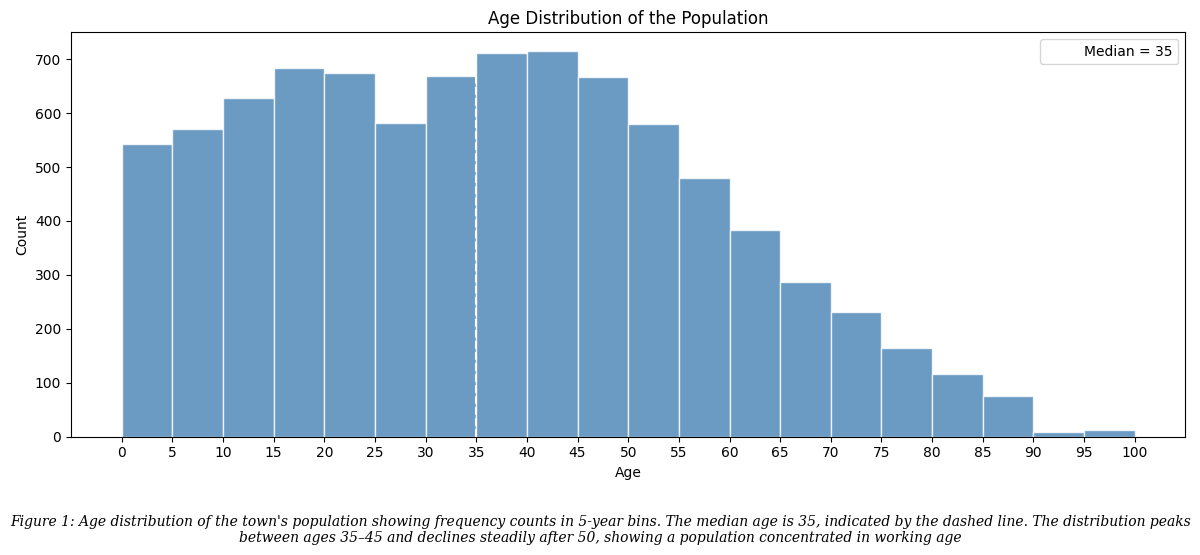

Mean age: 35.5
Median age: 35.0
Standard deviation: 21.5


In [190]:
# age distribution using the age column in hist plot
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(df['Age'], bins=range(0, 105, 5), edgecolor='white', alpha=0.8, color='steelblue')
ax.set_xlabel('Age')
ax.set_ylabel('Count')
ax.set_title('Age Distribution of the Population')
ax.set_xticks(range(0, 105, 5))
ax.axvline(df['Age'].median(), color='white', linestyle='--', linewidth=1.5, label=f'Median = {df["Age"].median():.0f}')
ax.legend()
plt.figtext(0.5, -0.09, 'Figure 1: Age distribution of the town\'s population showing frequency counts in 5-year bins. The median age is 35, indicated by the dashed line. The distribution peaks between ages 35–45 and declines steadily after 50, showing a population concentrated in working age', 
            ha='center', fontsize=10, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)

plt.tight_layout()
plt.savefig('age_distribution1.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Mean age: {df["Age"].mean():.1f}')
print(f'Median age: {df["Age"].median()}')
print(f'Standard deviation: {df["Age"].std():.1f}')

from this chart, I can tell that the population has its highest population around 40 to 60. and people start to decline / reduce from 50, 
there is decline.

Now, we need to check the religion and occupation. which religion is the most common in this population

* Age pyramid comparing the distribution, birth rate, death rate and gender of male and female in the population

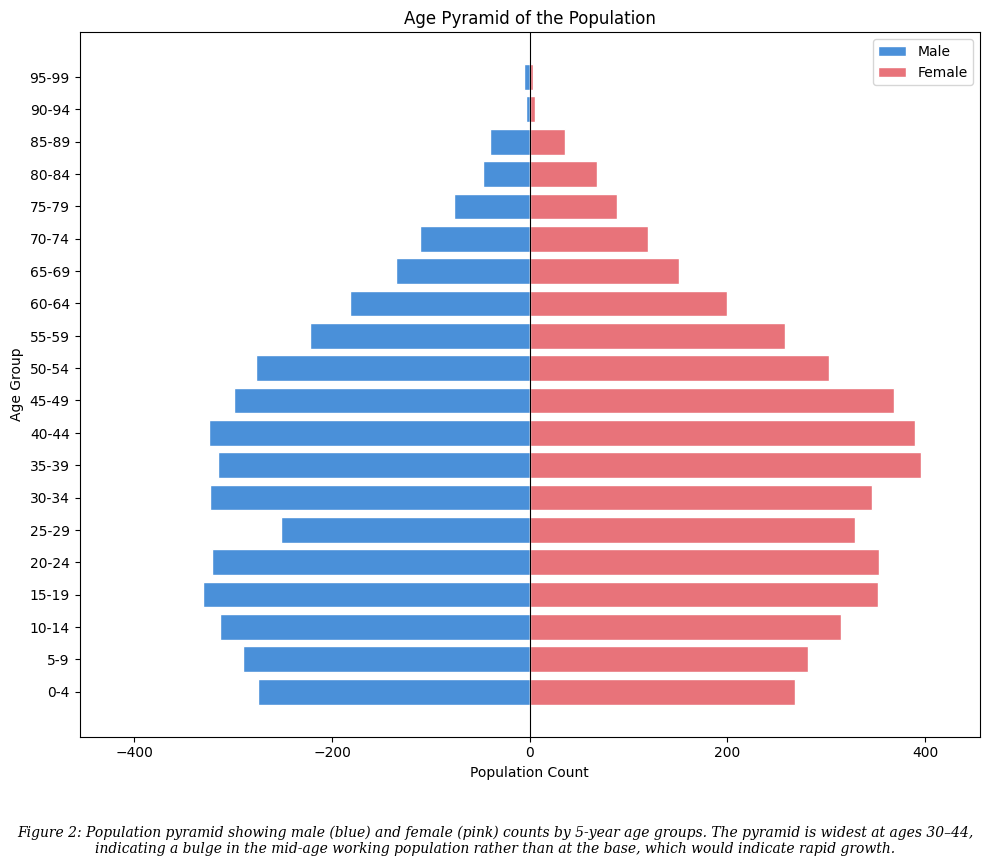

In [188]:
# using an age bin of a list of range
age_bins = list(range(0, 105, 5))
age_labels = [f'{i}-{i+4}' for i in range(0, 100, 5)]
df['Age_Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels, right=False)

# calculating the male_counts
male_counts = df[df['Gender'] == 'Male']['Age_Group'].value_counts().sort_index()
female_counts = df[df['Gender'] == 'Female']['Age_Group'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 8))

# adding the color, fill and the gender in a horizontal bar chart
y_pos = range(len(age_labels))
ax.barh(y_pos, -male_counts.reindex(age_labels, fill_value=0).values, align='center', 
        color='#4A90D9', label='Male', edgecolor='white', height=0.8)
ax.barh(y_pos, female_counts.reindex(age_labels, fill_value=0).values, align='center', 
        color='#E8737A', label='Female', edgecolor='white', height=0.8)

ax.set_yticks(y_pos)
ax.set_yticklabels(age_labels)
ax.set_xlabel('Population Count')
ax.set_ylabel('Age Group')
ax.set_title('Age Pyramid of the Population')

# Making x-axis labels absolute
max_val = max(male_counts.max(), female_counts.max())
ax.set_xlim(-max_val * 1.15, max_val * 1.15)

ax.legend(loc='upper right')
ax.axvline(0, color='black', linewidth=0.8)
plt.figtext(0.5, -0.07, 'Figure 2: Population pyramid showing male (blue) and female (pink) counts by 5-year age groups. The pyramid is widest at ages 30–44, indicating a bulge in the mid-age working population rather than at the base, which would indicate rapid growth.', 
            ha='center',  fontsize=10, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.tight_layout()
plt.savefig('population_pyramid1.png', dpi=150, bbox_inches='tight')
plt.show()

* the gender distribution of males and females

Gender distribution:
Gender
Female    4635
Male      4151
Name: count, dtype: int64

Male:Female ratio = 1:1.12


/var/folders/qr/1jjdl6z561xg7033nr5m08n00000gn/T/ipykernel_1134/3941275602.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gender_age = df.groupby(['Age_Group', 'Gender']).size().unstack(fill_value=0)


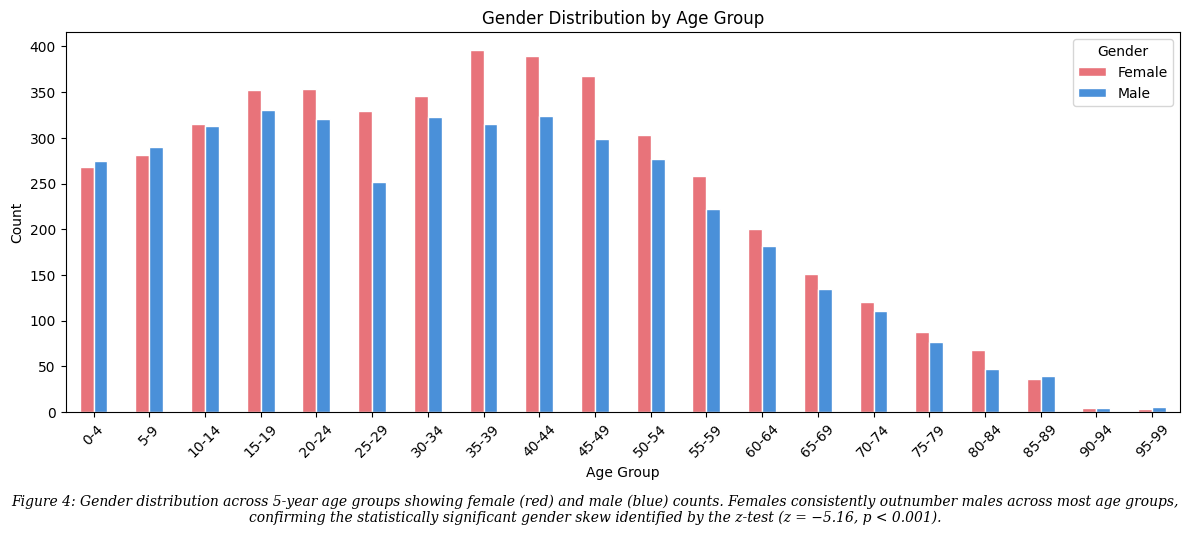

In [178]:
# females and males in the population
gender_counts = df['Gender'].value_counts()
print('Gender distribution:')
print(gender_counts)
print(f'\nMale:Female ratio = 1:{gender_counts["Female"]/gender_counts["Male"]:.2f}')

# Gender by age group
gender_age = df.groupby(['Age_Group', 'Gender']).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 5))
gender_age.plot(kind='bar', ax=ax, color=['#E8737A', '#4A90D9'], edgecolor='white')
ax.set_xlabel('Age Group')
ax.set_ylabel('Count')
ax.set_title('Gender Distribution by Age Group')
ax.legend(title='Gender')
plt.xticks(rotation=45)
plt.figtext(0.5, -0.05, 'Figure 4: Gender distribution across 5-year age groups showing female (red) and male (blue) counts. Females consistently outnumber males across most age groups, confirming the statistically significant gender skew identified by the z-test (z = −5.16, p < 0.001).', 
            ha='center', fontsize=10, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.tight_layout()
plt.savefig('gender_by_age1.png', dpi=150, bbox_inches='tight')
plt.show()

* Next, plotting bivariate plots to check relationships between different columns / features

* Starting with the age and marital Status, I'd check what age people marry, divorce and also if anyone lied about their age or marital status

In [117]:
# population ratio
children = len(df[df['Age'] < 18])
working_age = len(df[(df['Age'] >= 18) & (df['Age'] < 65)])
elderly = len(df[df['Age'] >= 65])
total = len(df)

print('Population ratio')
print(f'Children (0-17):     {children} ({children/total*100:.1f}%)')
print(f'Working age (18-64): {working_age} ({working_age/total*100:.1f}%)')
print(f'Elderly (65 and above):       {elderly} ({elderly/total*100:.1f}%)')

print(f'\nDependency ratio: {(children + elderly) / working_age * 100:.1f}%')
print(f'Old-age dependency ratio: {elderly / working_age * 100:.1f}%')
print(f'Child dependency ratio: {children / working_age * 100:.1f}%')

Population ratio
Children (0-17):     2142 (24.4%)
Working age (18-64): 5741 (65.3%)
Elderly (65 and above):       903 (10.3%)

Dependency ratio: 53.0%
Old-age dependency ratio: 15.7%
Child dependency ratio: 37.3%


* # Marital Distribution

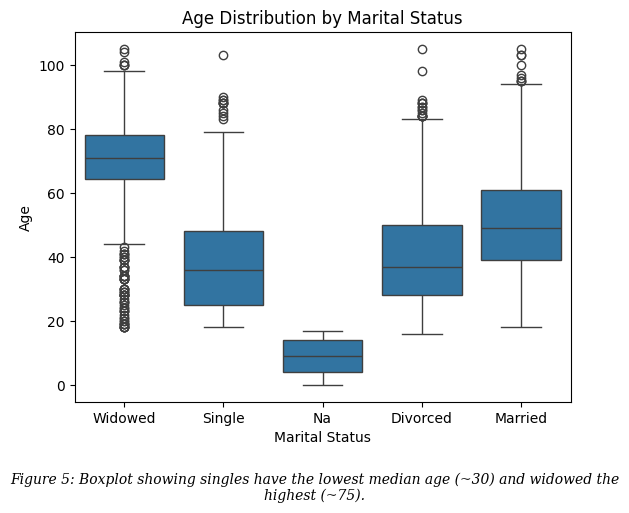

In [177]:
sns.boxplot(x='Marital Status', y='Age', data=df)
plt.title('Age Distribution by Marital Status')
plt.figtext(0.5, -0.09, 'Figure 5: Boxplot showing singles have the lowest median age (~30) and widowed the highest (~75).', 
            ha='center', fontsize=10, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.savefig('marital_status_and_age1.png', dpi=150, bbox_inches='tight')
plt.show()

/var/folders/qr/1jjdl6z561xg7033nr5m08n00000gn/T/ipykernel_1134/1789560680.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  marital_age = adults.groupby(['Age_Group', 'Marital Status']).size().unstack(fill_value=0)


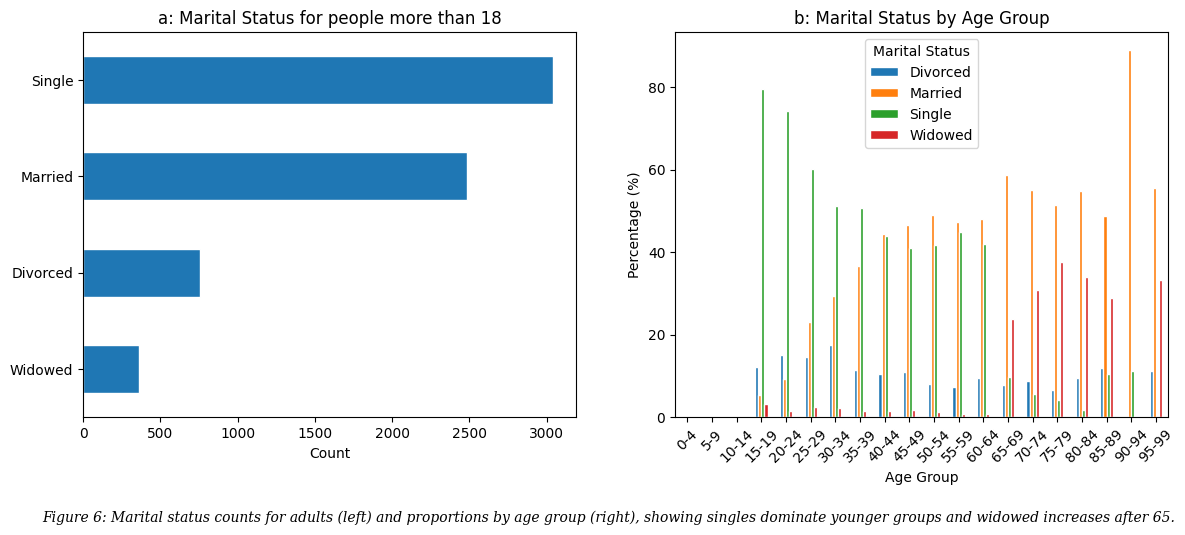


Singles (among adults): 45.8%
Marriage rate (among adults): 37.4%
Widowed (among adults): 5.4%
Divorce rate (among adults): 11.4%
Divorce-to-marriage ratio: 30.5%

Singles number: 3040
Married number: 2484
Widowed number: 362
Divorce number: 758


In [172]:
# Marriage status distribution
adults = df[df['Age'] >= 18]
marital_counts = adults['Marital Status'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# barchart
marital_counts.plot(kind='barh', ax=axes[0],  edgecolor='white')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('')
axes[0].set_title('a: Marital Status for people more than 18')
axes[0].invert_yaxis()

# Marriage status by age group
marital_age = adults.groupby(['Age_Group', 'Marital Status']).size().unstack(fill_value=0)
marital_age_pct = marital_age.div(marital_age.sum(axis=1), axis=0) * 100
marital_age_pct.plot(kind='bar',  ax=axes[1],edgecolor='white')
axes[1].set_xlabel('Age Group')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_title('b: Marital Status by Age Group')
plt.xticks(rotation=45)
plt.figtext(0.5, -0.10, 'Figure 6: Marital status counts for adults (left) and proportions by age group (right), showing singles dominate younger groups and widowed increases after 65.', 
            ha='center', fontsize=10, fontname='Times New Roman', fontfamily='serif',  style='italic', wrap=True)
# plt.tight_layout()
plt.savefig('marriage_status1.png', dpi=150, bbox_inches='tight')
plt.show()

# Marriage and divorce rates
singles = len(adults[adults['Marital Status'] == 'Single'])
married_count = len(adults[adults['Marital Status'] == 'Married'])
divorced_count = len(adults[adults['Marital Status'] == 'Divorced'])
widowed = len(adults[adults['Marital Status'] == 'Widowed'])
print(f'\nSingles (among adults): {singles/len(adults)*100:.1f}%')
print(f'Marriage rate (among adults): {married_count/len(adults)*100:.1f}%')
print(f'Widowed (among adults): {widowed/len(adults)*100:.1f}%')
print(f'Divorce rate (among adults): {divorced_count/len(adults)*100:.1f}%')
print(f'Divorce-to-marriage ratio: {divorced_count/married_count*100:.1f}%')



print(f'\nSingles number: {singles}')
print(f'Married number: {married_count}')
print(f'Widowed number: {widowed}')
print(f'Divorce number: {divorced_count}')


* # Employment and Unemployment Rate with Occupation

Gender               Female  Male
Occupation Category              
Child                   268   275
Employed               2486  2217
Retired                 363   335
Student                1167  1113
Unemployed              351   211


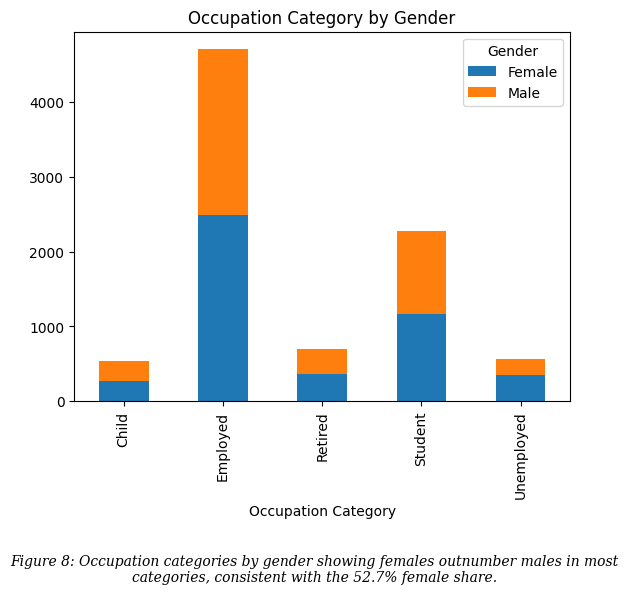

In [167]:
# gender and occupation category
conditions = [
    df['Occupation'] == 'Child',
    df['Occupation'].str.contains('Student', na=False),
    df['Occupation'].str.startswith('Retired', na=False),
    df['Occupation'] == 'Unemployed'
]

choices = ['Child', 'Student', 'Retired', 'Unemployed']

df['Occupation Category'] = np.select(conditions, choices, default='Employed')

gender_occupation = pd.crosstab(df['Occupation Category'], df['Gender'])
print(gender_occupation)

# Visualize it
gender_occupation.plot(kind='bar', stacked=True)
plt.title('Occupation Category by Gender')
plt.figtext(0.5, -0.26, 'Figure 8: Occupation categories by gender showing females outnumber males in most categories, consistent with the 52.7% female share.', 
            ha='center',   fontsize=10, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.savefig('occupation_and_age1.png', dpi=150, bbox_inches='tight')
plt.show()

In [121]:
# calculating occupancy
occupancy = df.groupby(['Street', 'House Number']).size()
print(f"Average Occupancy: {occupancy.mean():.2f} people per house")

Average Occupancy: 2.87 people per house


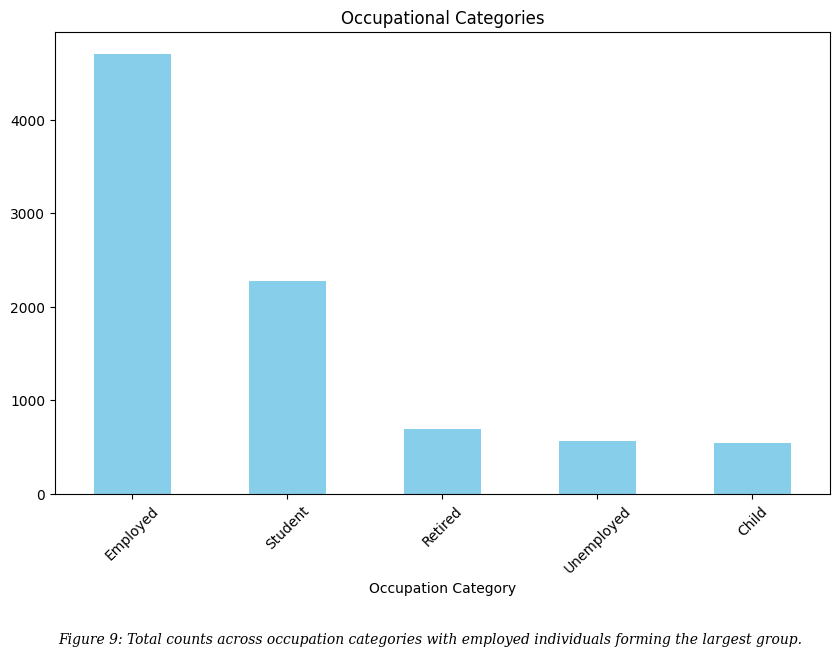

Occupation Category
Employed      4703
Student       2280
Retired        698
Unemployed     562
Child          543
Name: count, dtype: int64

In [160]:
# Employment Categories
plt.figure(figsize=(10, 6))
df['Occupation Category'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Occupational Categories')
plt.xticks(rotation=45)
plt.figtext(0.5, -0.14, 'Figure 9: Total counts across occupation categories with employed individuals forming the largest group.', 
            ha='center',  fontsize=12, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.savefig('occupation_and_age3.png', dpi=150, bbox_inches='tight')
plt.show()


df['Occupation Category'].value_counts()

In [123]:
df['Occupation'].unique()

array(['Retired Surveyor, Building Control', 'Financial Trader',
       'University Student', ..., 'Retired Doctor, General Practice',
       'Planning And Development Surveyor',
       'Retired Engineer, Communications'], dtype=object)

Next, Comparing Birth and Death Rates

In [124]:
# calculating to see who  is retired, a child, a student, unemployed and a university student
df['Is_Retired'] = df['Occupation'].str.startswith('Retired', na=False)
df['Is_Student'] = df['Occupation'].isin(['Student', 'University Student', 'Phd Student'])
df['Is_Unemployed'] = df['Occupation'] == 'Unemployed'
df['Is_Child'] = df['Occupation'] == 'Child'
df['Is_University_Student'] = df['Occupation'].isin(['University Student', 'Phd Student'])

print('Occupation category counts:')
print(f"  Retired:           {df['Is_Retired'].sum()}")
print(f"  Student (school):  {(df['Occupation'] == 'Student').sum()}")
print(f"  University Student:{(df['Occupation'] == 'University Student').sum()}")

print(f"  PhD Student:       {(df['Occupation'] == 'Phd Student').sum()}")
print(f"  Unemployed:        {df['Is_Unemployed'].sum()}")
print(f"  Child:             {df['Is_Child'].sum()}")
print(f"  Working adults:    {(~df['Is_Retired'] & ~df['Is_Student'] & ~df['Is_Unemployed'] & ~df['Is_Child']).sum()}")

Occupation category counts:
  Retired:           698
  Student (school):  1699
  University Student:560
  PhD Student:       21
  Unemployed:        562
  Child:             543
  Working adults:    4703


Working-age population (18-64, excluding students & retired): 5059
Unemployed in this group: 524
Unemployment rate: 10.4%


/var/folders/qr/1jjdl6z561xg7033nr5m08n00000gn/T/ipykernel_1134/3405863136.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  unemployed_by_age = working_pop.groupby('Age_Group')['Is_Unemployed'].mean() * 100


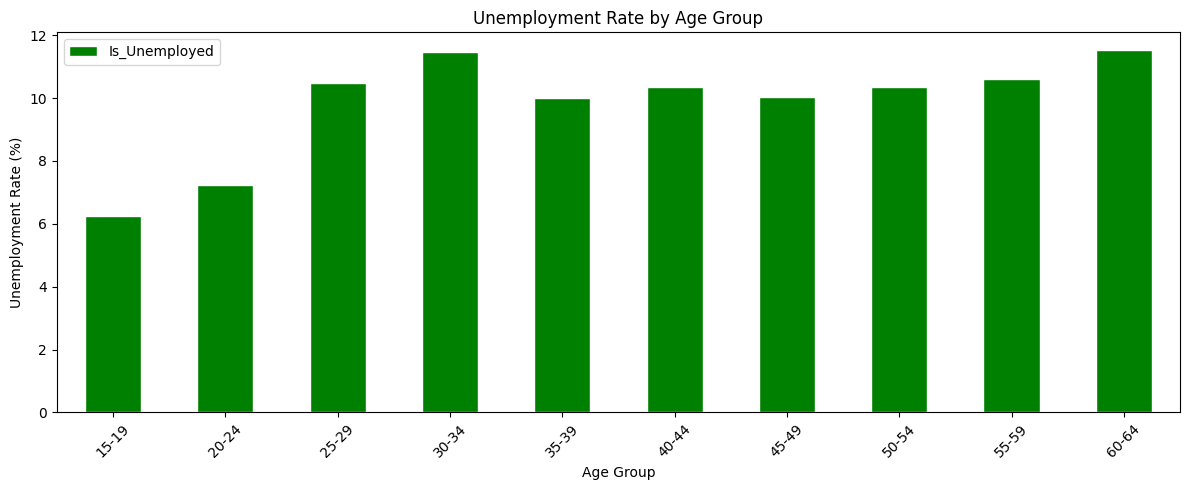


Unemployment by gender:
  Male: 8.3%
  Female: 12.2%


In [125]:
# Unemployment rate
working_pop = df[(df['Age'] >= 18) & (df['Age'] < 65) & (~df['Is_Student']) & (~df['Is_Retired'])]
unemployed = working_pop[working_pop['Is_Unemployed']]

unemployment_rate = len(unemployed) / len(working_pop) * 100
print(f'Working-age population (18-64, excluding students & retired): {len(working_pop)}')
print(f'Unemployed in this group: {len(unemployed)}')
print(f'Unemployment rate: {unemployment_rate:.1f}%')

# Unemployment by age group
unemployed_by_age = working_pop.groupby('Age_Group')['Is_Unemployed'].mean() * 100

fig, ax = plt.subplots(figsize=(12, 5))
# working-age groups
unemployed_by_age = unemployed_by_age[unemployed_by_age.index.isin(
    [f'{i}-{i+4}' for i in range(15, 65, 5)]
)]
unemployed_by_age.plot(kind='bar', ax=ax, color='green', edgecolor='white')
ax.set_xlabel('Age Group')
ax.set_ylabel('Unemployment Rate (%)')
ax.set_title('Unemployment Rate by Age Group')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('age_unemployment.png', dpi=150, bbox_inches='tight')
plt.show()

# Unemployment by gender
print('\nUnemployment by gender:')
for g in ['Male', 'Female']:
    group = working_pop[working_pop['Gender'] == g]
    rate = group['Is_Unemployed'].mean() * 100
    print(f'  {g}: {rate:.1f}%')

In [126]:
# Two-proportion z-test: Young adult vs older worker unemployment
working_pop = df[(df['Age'] >= 18) & (df['Age'] < 65) & (~df['Occupation'].isin(['Student', 'University Student', 'Phd Student'])) & (~df['Occupation'].str.startswith('Retired', na=False))]

young_adults = working_pop[(working_pop['Age'] >= 18) & (working_pop['Age'] <= 24)]
older_workers = working_pop[working_pop['Age'] > 24]

n1 = len(young_adults)
x1 = (young_adults['Occupation'] == 'Unemployed').sum()
p1 = x1 / n1

n2 = len(older_workers)
x2 = (older_workers['Occupation'] == 'Unemployed').sum()
p2 = x2 / n2

p_pool = (x1 + x2) / (n1 + n2)
se = np.sqrt(p_pool * (1 - p_pool) * (1/n1 + 1/n2))
z_stat = (p1 - p2) / se
p_value = 2 * (1 - stats.norm.cdf(abs(z_stat)))

print(f'Young adults (18-24) unemployment rate: {p1*100:.1f}% (n={n1})')
print(f'Older workers (25-64) unemployment rate: {p2*100:.1f}% (n={n2})')
print(f'Z-statistic: {z_stat:.3f}')
print(f'P-value: {p_value:.4f}')
print(f'Result: {"Reject H0" if p_value < 0.05 else "Fail to reject H0"} at α = 0.05')

Young adults (18-24) unemployment rate: 7.2% (n=292)
Older workers (25-64) unemployment rate: 10.6% (n=4767)
Z-statistic: -1.829
P-value: 0.0674
Result: Fail to reject H0 at α = 0.05


* # Occupations

to count people per address

In [127]:
occupation_count = df['Occupation'].value_counts()
total = len(df)

for occ, count in occupation_count.items():
    print(f'{occ}: {count} ({count/total*100:.1f}%)')

Student: 1699 (19.3%)
Unemployed: 562 (6.4%)
University Student: 560 (6.4%)
Child: 543 (6.2%)
Phd Student: 21 (0.2%)
Scientist, Physiological: 17 (0.2%)
Freight Forwarder: 16 (0.2%)
Osteopath: 15 (0.2%)
Management Consultant: 15 (0.2%)
Location Manager: 15 (0.2%)
Therapist, Occupational: 15 (0.2%)
Optometrist: 14 (0.2%)
Chief Executive Officer: 14 (0.2%)
Administrator, Civil Service: 14 (0.2%)
Claims Inspector/Assessor: 14 (0.2%)
Structural Engineer: 14 (0.2%)
Immunologist: 14 (0.2%)
Buyer, Industrial: 13 (0.1%)
Careers Adviser: 13 (0.1%)
Illustrator: 13 (0.1%)
Dealer: 13 (0.1%)
Ophthalmologist: 13 (0.1%)
Media Buyer: 13 (0.1%)
Rural Practice Surveyor: 13 (0.1%)
Editor, Magazine Features: 13 (0.1%)
Manufacturing Systems Engineer: 13 (0.1%)
Psychologist, Counselling: 13 (0.1%)
Engineer, Maintenance (It): 13 (0.1%)
Museum Education Officer: 13 (0.1%)
Merchant Navy Officer: 13 (0.1%)
Analytical Chemist: 12 (0.1%)
Engineer, Agricultural: 12 (0.1%)
Scientist, Clinical (Histocompatibility An

In [128]:
for occ, count in occupation_count.head(20).items():
    print(f'{occ}: {count} ({count/total*100:.1f}%)')

Student: 1699 (19.3%)
Unemployed: 562 (6.4%)
University Student: 560 (6.4%)
Child: 543 (6.2%)
Phd Student: 21 (0.2%)
Scientist, Physiological: 17 (0.2%)
Freight Forwarder: 16 (0.2%)
Osteopath: 15 (0.2%)
Management Consultant: 15 (0.2%)
Location Manager: 15 (0.2%)
Therapist, Occupational: 15 (0.2%)
Optometrist: 14 (0.2%)
Chief Executive Officer: 14 (0.2%)
Administrator, Civil Service: 14 (0.2%)
Claims Inspector/Assessor: 14 (0.2%)
Structural Engineer: 14 (0.2%)
Immunologist: 14 (0.2%)
Buyer, Industrial: 13 (0.1%)
Careers Adviser: 13 (0.1%)
Illustrator: 13 (0.1%)


In [129]:
df['Occupation'].nunique()

1066

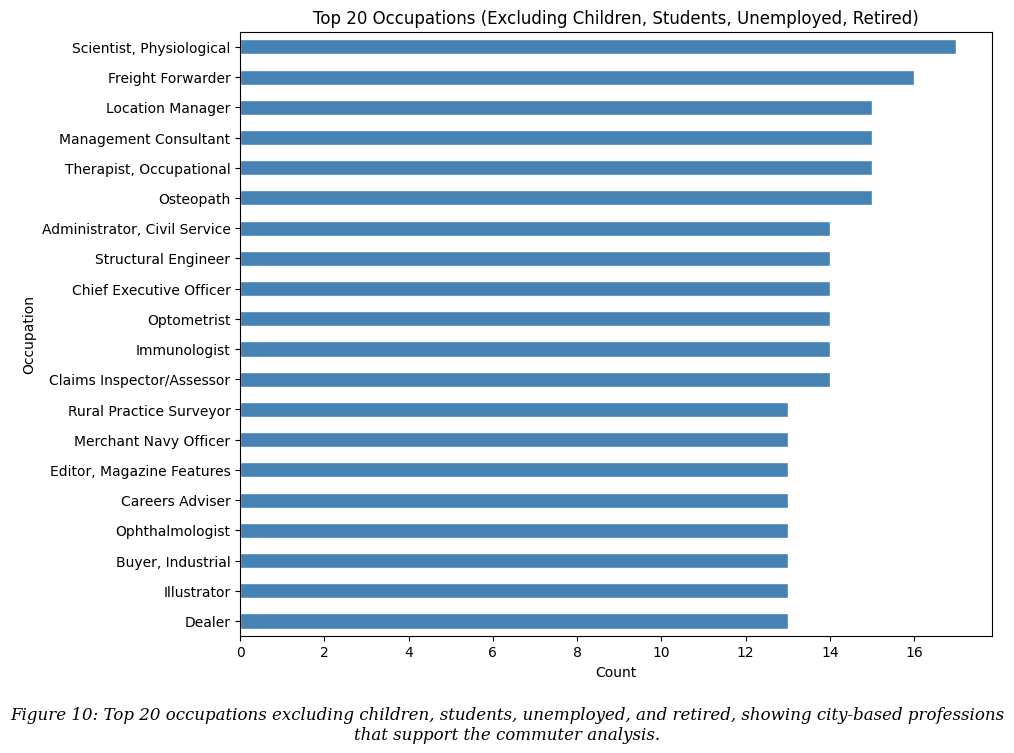

In [155]:
# Top 20 occupations (excluding Child, Student, Unemployed, Retired)
working_occs = df[
    ~df['Is_Child'] & ~df['Is_Student'] & ~df['Is_Unemployed'] & ~df['Is_Retired']
]['Occupation'].value_counts().head(20)

fig, ax = plt.subplots(figsize=(10, 7))
working_occs.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Count')
ax.set_ylabel('Occupation')
ax.set_title('Top 20 Occupations (Excluding Children, Students, Unemployed, Retired)')
ax.invert_yaxis()
plt.figtext(0.5, -0.06, 'Figure 10: Top 20 occupations excluding children, students, unemployed, and retired, showing city-based professions that support the commuter analysis.', 
            ha='center',  fontsize=12, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.tight_layout()
plt.savefig('top_occupations1.png', dpi=150, bbox_inches='tight')
plt.show()

* # Household Occupancy

In [131]:
df.groupby(['Street', 'House Number']).size()

Street                 House Number
Akhtar Cove            1                2
                       2                2
                       3                1
                       4                5
Akhtar Drive           1                2
                       2                1
                       3                1
                       4                2
Alberthook Lane        1                2
                       2                1
                       3                2
                       4                2
                       5                1
                       6                1
                       7                2
                       8                1
                       9                4
                       10               1
                       11               1
                       12               1
                       13               1
                       14               2
                       15               

In [132]:
# this calculates the household size using the street and house number
household_sizes = df.groupby(['Street', 'House Number']).size()
print(f'Total households: {len(household_sizes)}')
print(f'Average size: {household_sizes.mean():.2f}')

Total households: 3063
Average size: 2.87


In [133]:
# defining the house details and count
df['House_detail'] = df['Street'] + '_' + df['House Number'].astype(str)
house_count = df.groupby('House_detail').size()

In [134]:
# Households with children, checking the number of households with children

households_with_children = df[df['Age'] < 18].groupby('House_detail').size()
family_households = df[df['House_detail'].isin(households_with_children.index)].groupby('House_detail').size()

print(f'Households with children: {len(households_with_children)}')
print(f'Average size of households with children: {family_households.mean():.2f}')
print(f'Average number of children per family household: {households_with_children.mean():.2f}')

Households with children: 1230
Average size of households with children: 3.98
Average number of children per family household: 1.74


Average Household Size: 2.87 people


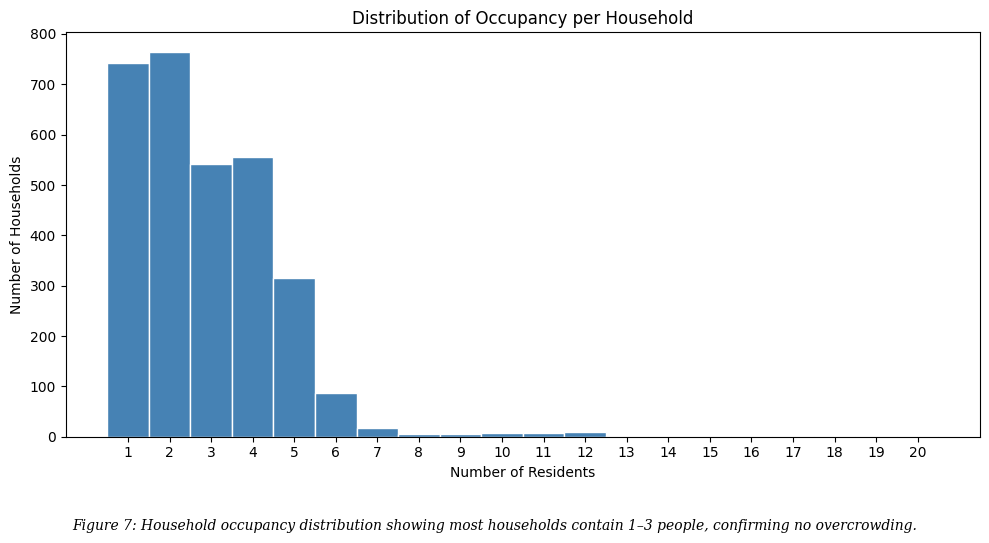

In [169]:
# calculating the size of the household
household_sizes = df.groupby(['Street', 'House Number']).size()
print(f"Average Household Size: {household_sizes.mean():.2f} people")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(household_sizes, bins=range(1, household_sizes.max() + 2), 
        edgecolor='white', color='steelblue', align='left')
ax.set_xlabel('Number of Residents')
ax.set_ylabel('Number of Households')
ax.set_title('Distribution of Occupancy per Household')
ax.set_xticks(range(1, household_sizes.max() + 1))
plt.figtext(0.5, -0.07, 'Figure 7: Household occupancy distribution showing most households contain 1–3 people, confirming no overcrowding.', 
            ha='center', fontsize=10, fontname='Times New Roman', fontfamily='serif',  style='italic', wrap=True)
plt.tight_layout()
plt.savefig('household_distribution1.png', dpi=150, bbox_inches='tight')
plt.show()

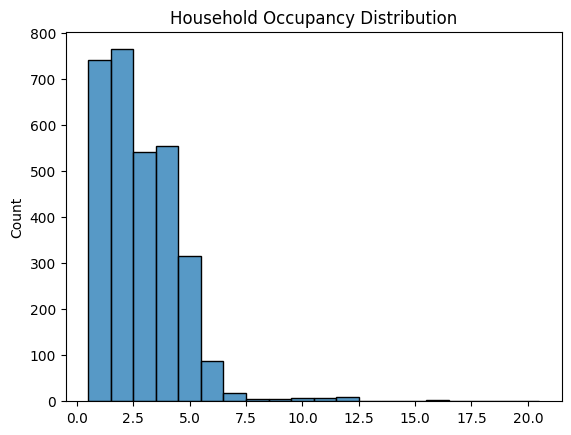

In [136]:
# plotting for household occupancy
sns.histplot(occupancy, discrete=True)
plt.title('Household Occupancy Distribution')
plt.show()

# * Religion

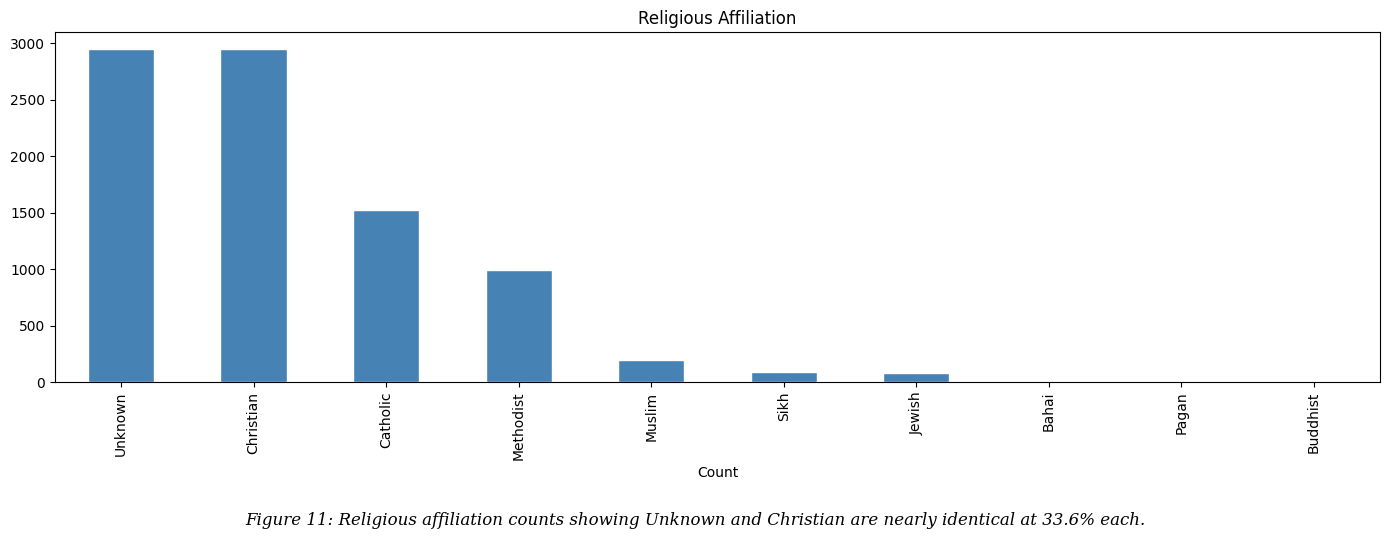

Religions of people in this population
  Unknown: 2949 (33.6% of total pop)
  Christian: 2948 (33.6% of total pop)
  Catholic: 1524 (17.3% of total pop)
  Methodist: 992 (11.3% of total pop)
  Muslim: 197 (2.2% of total pop)
  Sikh: 86 (1.0% of total pop)
  Jewish: 80 (0.9% of total pop)
  Bahai: 5 (0.1% of total pop)
  Pagan: 3 (0.0% of total pop)
  Buddhist: 2 (0.0% of total pop)


In [153]:
# Religion distribution 
religion_counts = df['Religion'].value_counts()
religion_stated = religion_counts[religion_counts.index != '']

fig, axes = plt.subplots(1, figsize=(14, 5))

# All religions including unknown
religion_counts.plot(kind='bar',  color='steelblue', edgecolor='white')
axes.set_xlabel('Count')
axes.set_title('Religious Affiliation')
plt.figtext(0.5, -0.06, 'Figure 11: Religious affiliation counts showing Unknown and Christian are nearly identical at 33.6% each.', 
            ha='center',  fontsize=12, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.tight_layout()
plt.savefig('religion_affiliations1.png', dpi=150, bbox_inches='tight')
plt.show()

print('Religions of people in this population')
for rel, count in religion_stated.items():
    print(f'  {rel}: {count} ({count/len(df)*100:.1f}% of total pop)')

* Calculating the religion by age group

/var/folders/qr/1jjdl6z561xg7033nr5m08n00000gn/T/ipykernel_1134/97043529.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  religion_age = df_religion.groupby(['Age_Group', 'Religion']).size().unstack(fill_value=0)


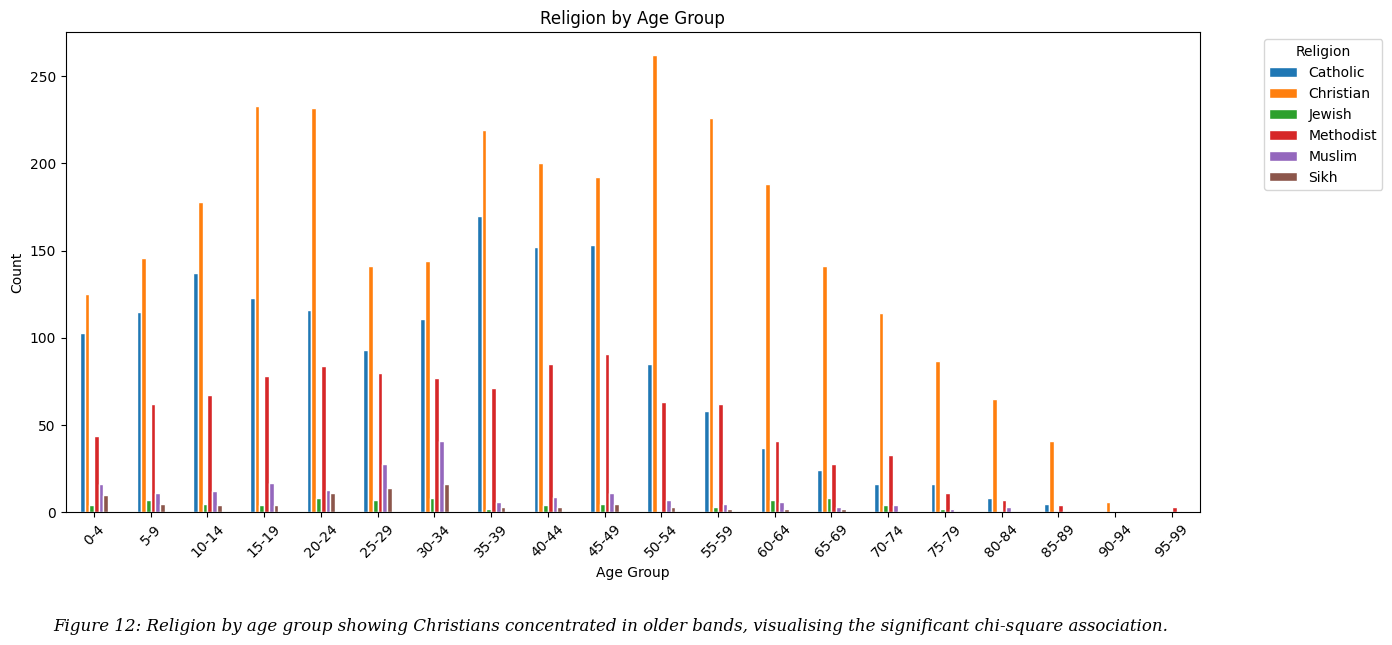

In [138]:
# Religion by age group checking to see if any religions are growing among younger demographics
major_religions = ['Christian', 'Catholic', 'Methodist', 'Muslim', 'Jewish', 'Sikh']
df_religion = df[df['Religion'].isin(major_religions)]

religion_age = df_religion.groupby(['Age_Group', 'Religion']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 6))
religion_age.plot(kind='bar', ax=ax, edgecolor='white')
ax.set_xlabel('Age Group')
ax.set_ylabel('Count')
ax.set_title('Religion by Age Group')
ax.legend(title='Religion', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.figtext(0.44, -0.06, 'Figure 12: Religion by age group showing Christians concentrated in older bands, visualising the significant chi-square association.', 
            ha='center',  fontsize=12, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.tight_layout()
plt.savefig('religion_by_age1.png', dpi=150, bbox_inches='tight')
plt.show()

In [139]:
# Chi-square test: Religion vs Age Group

df['Age_Category'] = pd.cut(df['Age'], bins=[0, 18, 30, 50, 65, 120], 
                            labels=['0-17', '18-29', '30-49', '50-64', '65'])

# this gets the major religions in the town
major_religions = ['Christian', 'Catholic', 'Methodist', 'Muslim', 'Jewish', 'Sikh']
religion_test = df[df['Religion'].isin(major_religions)]

contingency = pd.crosstab(religion_test['Age_Category'], religion_test['Religion'])
chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f'Chi-square statistic: {chi2:.2f}')
print(f'Degrees of freedom: {dof}')
print(f'P-value: {p_value:.4f}')
print(f'Result: {"Reject H0" if p_value < 0.05 else "Fail to reject H0"} at α = 0.05')
print(f'\nContingency table:')
print(contingency)

Chi-square statistic: 358.84
Degrees of freedom: 20
P-value: 0.0000
Result: Reject H0 at α = 0.05

Contingency table:
Religion      Catholic  Christian  Jewish  Methodist  Muslim  Sikh
Age_Category                                                      
0-17               428        614      18        230      45    18
18-29              254        451      18        198      57    29
30-49              603        766      17        319      62    25
50-64              155        678      11        160      16     8
65                  63        422      15         80      15     3


* # Birth and Death Rate of the Population

In [140]:
# Birth Rate Calculation
infants = len(df[df['Age'] == 0])
birth_rate = (infants / len(df)) * 1000
print(f"Estimated Birth Rate: {birth_rate:.2f} per 1000 people")

Estimated Birth Rate: 11.15 per 1000 people


In [141]:
# this calculates birthrate in 100000
births = len(df[df['Age'] == 0])
total_population = len(df)
birth_rate_per_100000 = (births/total_population) * 100000
print(f"Estimated Birth Rate: {birth_rate_per_100000:.2f} per 100000 people")

Estimated Birth Rate: 1115.41 per 100000 people


In [142]:
# Counting infants (Workshop 5, Ex 3a)
births = len(df[df['Age'] == 0])
total_pop = len(df)
birth_rate_per_1000 = (births / total_pop) * 1000
print(f"Estimated Birth Rate: {birth_rate_per_1000:.2f} per 1000 people")

Estimated Birth Rate: 11.15 per 1000 people


In [143]:
# Identify infants (Age 0)
infants = len(df[df['Age'] == 0])
total_pop = len(df)

# Calculate Crude Birth Rate (per 1000 people)
birth_rate = (infants / total_pop) * 1000

print(f"Total Population: {total_pop}")
print(f"Number of Births (Age 0): {infants}")
print(f"Calculated Birth Rate: {birth_rate:.2f} per 1000")

Total Population: 8786
Number of Births (Age 0): 98
Calculated Birth Rate: 11.15 per 1000


* Death rate Age Group 1: Calculating Death rate from 56 to 60 and 61 to 65

In [144]:
# the length of people less than  61 and greater than 54 minus the length of people less than 66 and greater than 60, divided by 5
deathRateFiveYears =(len(df[(df['Age'] >= 56) & (df['Age'] <= 60)])  -  len(df[(df['Age'] >= 61) & (df['Age'] <= 65)]))/5
print('Death rates in 5 years for the 56 to 65:', deathRateFiveYears)

#to get the deathrate per 100000
deathRatesInHun = deathRateFiveYears * 100000
print(f'Death Rates in 100000: {deathRatesInHun}')

Death rates in 5 years for the 56 to 65: 16.0
Death Rates in 100000: 1600000.0


* Death rate Age Group 1: Calculating Death rate from 66 to 70 and 71 to 75

In [145]:
# the length of people less than 71 and greater than 64 minus the length of people less than 76 and greater than 70, divided by 5
deathRateFiveYears= (len(df[(df['Age'] >= 66) & (df['Age'] <= 70)])  -  len(df[(df['Age'] >= 71) & (df['Age'] <= 75)]))/5
print('Death rates in 5 years for the 66 to 75:', deathRateFiveYears)


#to get the death rate per 100000
deathRatesInHun = deathRateFiveYears * 100000
print(f'Death Rates in 100000: {deathRatesInHun}')

Death rates in 5 years for the 66 to 75: 3.0
Death Rates in 100000: 300000.0


* # Commuters Population

In [146]:
# Check: Children under 18
child_age_issues = df[(df['Is_Child']) & (df['Age'] >= 18)]
print(f'Children aged 18+: {len(child_age_issues)}')
if len(child_age_issues) > 0:
    print(child_age_issues[['First Name', 'Surname', 'Age', 'Occupation']].head())

# Check: Retired individuals should typically be 50+
young_retired = df[(df['Is_Retired']) & (df['Age'] < 50)]
print(f'\nRetired individuals under 50: {len(young_retired)}')
if len(young_retired) > 0:
    print(young_retired[['First Name', 'Surname', 'Age', 'Occupation']].head())

# Check: University students should typically be 17-35
unusual_students = df[(df['Is_University_Student']) & ((df['Age'] < 17) | (df['Age'] > 50))]
print(f'\nUniversity students with unusual ages (<17 or >50): {len(unusual_students)}')
if len(unusual_students) > 0:
    print(unusual_students[['First Name', 'Surname', 'Age', 'Occupation']].head())

Children aged 18+: 0

Retired individuals under 50: 0

University students with unusual ages (<17 or >50): 0


University Students: 560
PhD Students: 0
Total university-level commuters: 581
Proportion of total population: 6.6%


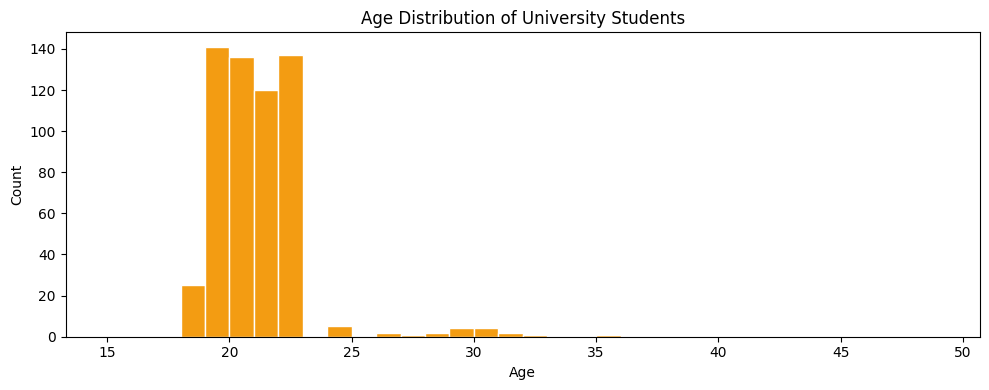

In [147]:
# University students (all commuters since no university in town)
uni_students = df[df['Is_University_Student']]
print(f'University Students: {len(uni_students[uni_students["Occupation"] == "University Student"])}')
print(f'PhD Students: {len(uni_students[uni_students["Occupation"] == "PhD Student"])}')
print(f'Total university-level commuters: {len(uni_students)}')
print(f'Proportion of total population: {len(uni_students)/len(df)*100:.1f}%')

# Age distribution of university students
fig, ax = plt.subplots(figsize=(10, 4))
uni_students['Age'].hist(bins=range(15, 50), ax=ax, color='#F39C12', edgecolor='white')
ax.grid(False)

ax.set_xlabel('Age')
ax.set_ylabel('Count')
ax.set_title('Age Distribution of University Students')
plt.tight_layout()
plt.savefig('university_students.png', dpi=150, bbox_inches='tight')
plt.show()

In [148]:
#Understanding the commuters in this population
commuter_keywords = ['CEO', 'Chief', 'Director', 'Manager', 'Consultant', 'Financial',
                      'Banker', 'Broker', 'Trader', 'Solicitor', 'Barrister', 'Lawyer',
                      'Analyst', 'Accountant']

def commuter_population(occupation):
    """Determine if an occupation likely requires commuting to a nearby city."""
    if pd.isna(occupation):
        return False
    occ_upper = occupation.upper()
    for keyword in commuter_keywords:
        if keyword.upper() in occ_upper:
            return True
    return False

df['commuter_population'] = df['Occupation'].apply(commuter_population) | df['Is_University_Student']

commuter_count = df['commuter_population'].sum()
print(f'Estimated commuters (university students + city-based professions): {commuter_count}')
print(f'Commuters of working-age population: {commuter_count / len(df[(df["Age"] >= 18) & (df["Age"] < 65)]) * 100:.1f}%')

# Top commuter occupations
print('\nTop likely commuter occupations:')
commuter_occs = df[df['commuter_population']]['Occupation'].value_counts().head(15)
print(commuter_occs.to_string())

Estimated commuters (university students + city-based professions): 1421
Commuters of working-age population: 24.8%

Top likely commuter occupations:
Occupation
University Student                     560
Phd Student                             21
Location Manager                        15
Management Consultant                   15
Chief Executive Officer                 14
Chief Financial Officer                 12
Hotel Manager                           12
Chief Operating Officer                 12
Facilities Manager                      12
Chartered Public Finance Accountant     11
Financial Trader                        11
Office Manager                          10
Retail Banker                           10
Product Manager                         10
Bonds Trader                            10


* grouping the population into schooling. adulting , elderly and retired

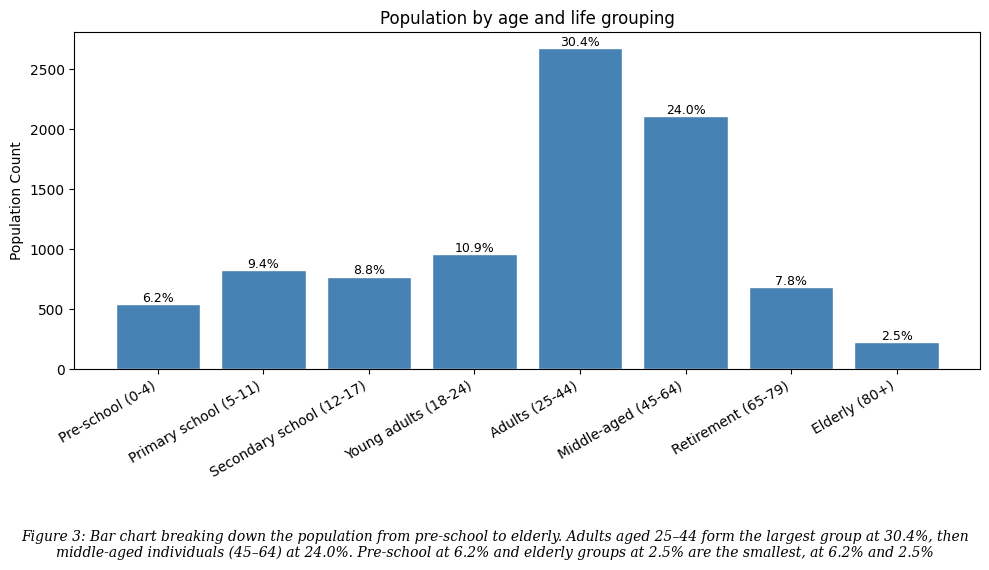

        activityGrouping  Count  Percentage
        Pre-school (0-4)    543         6.2
   Primary school (5-11)    828         9.4
Secondary school (12-17)    771         8.8
    Young adults (18-24)    957        10.9
          Adults (25-44)   2675        30.4
     Middle-aged (45-64)   2109        24.0
      Retirement (65-79)    682         7.8
           Elderly (80+)    221         2.5


In [187]:
# this groups the population into different life groups based on their ages
activityGrouping = {
    'Pre-school (0-4)': len(df[(df['Age'] >= 0) & (df['Age'] <= 4)]),
    'Primary school (5-11)': len(df[(df['Age'] >= 5) & (df['Age'] <= 11)]),
    'Secondary school (12-17)': len(df[(df['Age'] >= 12) & (df['Age'] <= 17)]),
    'Young adults (18-24)': len(df[(df['Age'] >= 18) & (df['Age'] <= 24)]),
    'Adults (25-44)': len(df[(df['Age'] >= 25) & (df['Age'] <= 44)]),
    'Middle-aged (45-64)': len(df[(df['Age'] >= 45) & (df['Age'] <= 64)]),
    'Retirement (65-79)': len(df[(df['Age'] >= 65) & (df['Age'] <= 79)]),
    'Elderly (80+)': len(df[df['Age'] >= 80])
}

activityGrouping_df = pd.DataFrame(list(activityGrouping.items()), columns=['activityGrouping', 'Count'])
activityGrouping_df['Percentage'] = (activityGrouping_df['Count'] / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(activityGrouping_df['activityGrouping'], activityGrouping_df['Count'], color='steelblue', edgecolor='white')
ax.set_ylabel('Population Count')
ax.set_title('Population by age and life grouping')
plt.xticks(rotation=30, ha='right')

# Add value labels
for bar, pct in zip(bars, activityGrouping_df['Percentage']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20, 
            f'{pct}%', ha='center', fontsize=9)
plt.figtext(0.5, -0.12, 'Figure 3: Bar chart breaking down the population from pre-school to elderly. Adults aged 25–44 form the largest group at 30.4%, then middle-aged individuals (45–64) at 24.0%. Pre-school at 6.2% and elderly groups at 2.5% are the smallest, at 6.2% and 2.5%', 
            ha='center', fontsize=10, fontname='Times New Roman', fontfamily='serif',  style='italic', wrap=True)

plt.tight_layout()
plt.savefig('life_stage_activityGrouping1.png', dpi=150, bbox_inches='tight')
plt.show()

print(activityGrouping_df.to_string(index=False))

Retirement
Currently retired (by occupation): 698
Currently aged 65 and above: 903
Approaching retirement (55-64): 862

In ~10 years, approximately 862 additional people will reach retirement age.
This represents a 95% increase in the 65 and above population.


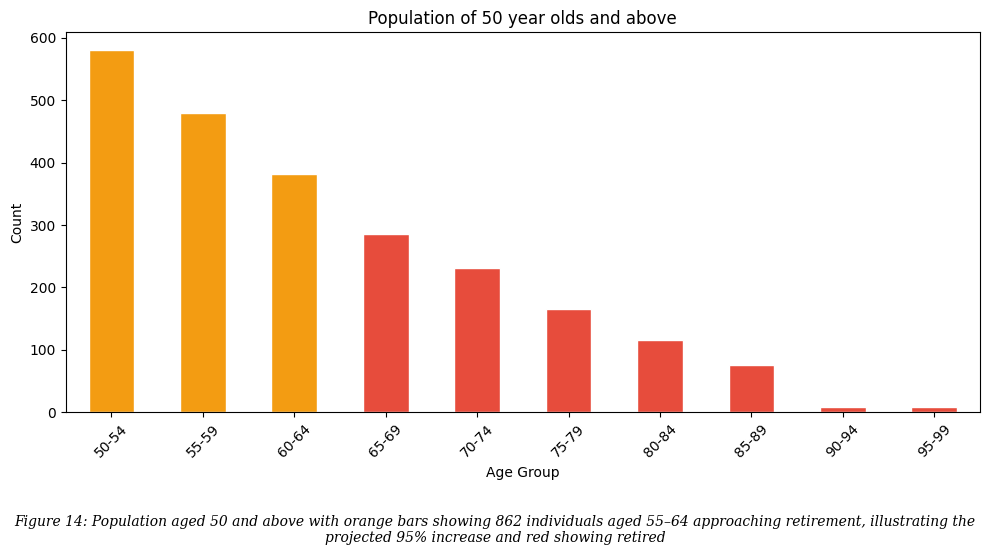

In [150]:
# People approaching retirement (55-64) vs currently retired
approaching_retirement = len(df[(df['Age'] >= 55) & (df['Age'] <= 64)])
currently_retired = df['Is_Retired'].sum()
aged_65_plus = len(df[df['Age'] >= 65])

print('Retirement')
print(f'Currently retired (by occupation): {currently_retired}')
print(f'Currently aged 65 and above: {aged_65_plus}')
print(f'Approaching retirement (55-64): {approaching_retirement}')
print(f'\nIn ~10 years, approximately {approaching_retirement} additional people will reach retirement age.')
print(f'This represents a {approaching_retirement/aged_65_plus*100:.0f}% increase in the 65 and above population.')

# retirement plot
fig, ax = plt.subplots(figsize=(10, 5))
age_50_plus = df[df['Age'] >= 50]
age_bins_retirement = list(range(50, 105, 5))
age_labels_ret = [f'{i}-{i+4}' for i in range(50, 100, 5)]
age_50_plus_grouped = pd.cut(age_50_plus['Age'], bins=age_bins_retirement, labels=age_labels_ret, right=False)
age_50_plus_grouped.value_counts().sort_index().plot(kind='bar', ax=ax, 
    color=['#F39C12' if i < 3 else '#E74C3C' for i in range(len(age_labels_ret))], edgecolor='white')
ax.set_xlabel('Age Group')
ax.set_ylabel('Count')
ax.set_title('Population of 50 year olds and above')
plt.xticks(rotation=45)
plt.figtext(0.5, -0.09, 'Figure 14: Population aged 50 and above with orange bars showing 862 individuals aged 55–64 approaching retirement, illustrating the projected 95% increase and red showing retired', 
            ha='center', fontsize=10, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.tight_layout()
plt.savefig('retirement_projection1.png', dpi=150, bbox_inches='tight')
plt.show()

# * Infirmity

People with recorded infirmities: 63 (0.72% of population)

Infirmity breakdown:
Infirmity
Physical Disability    18
Disabled               12
Mental Disability      10
Blind                   8
Deaf                    8
Unknown Infection       7
Name: count, dtype: int64


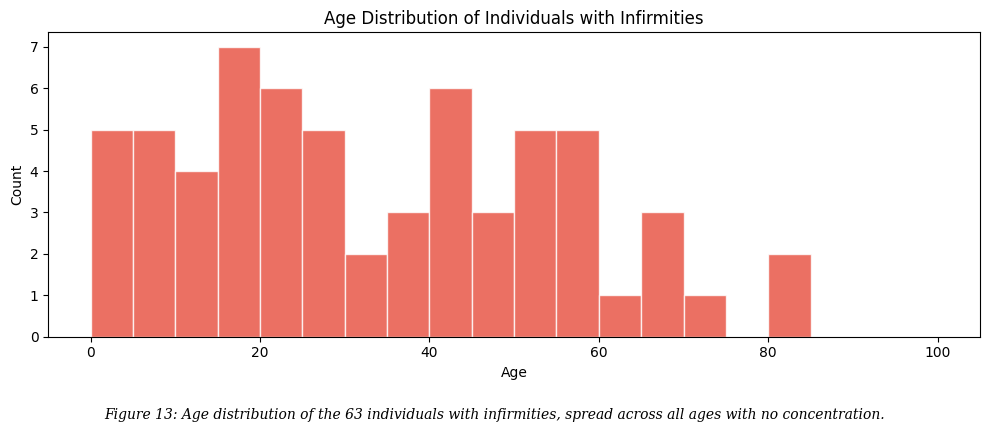

In [151]:
# Infirmity distribution
infirmity = df[(df['Infirmity'] != 'None') & (df['Infirmity'] != 'Unknown')]
print(f'People with recorded infirmities: {len(infirmity)} ({len(infirmity)/len(df)*100:.2f}% of population)')
print('\nInfirmity breakdown:')
print(infirmity['Infirmity'].value_counts())

# Age distribution of people with infirmities
if len(infirmity) > 0:
    fig, ax = plt.subplots(figsize=(10, 4))
    
    infirmity['Age'].hist(bins=range(0, 105, 5), ax=ax, color='#E74C3C', edgecolor='white', alpha=0.8)
    
    ax.grid(False)
    
    # Set labels and title
    ax.set_xlabel('Age')
    ax.set_ylabel('Count')
    ax.set_title('Age Distribution of Individuals with Infirmities')
    
    plt.figtext(0.5, -0.06, 'Figure 13: Age distribution of the 63 individuals with infirmities, spread across all ages with no concentration.', 
            ha='center',  fontsize=10, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
    plt.tight_layout()
    plt.savefig('infirmity_and_age1.png', dpi=150, bbox_inches='tight')
    plt.show()

# 

* # Summary of the charts and comparison

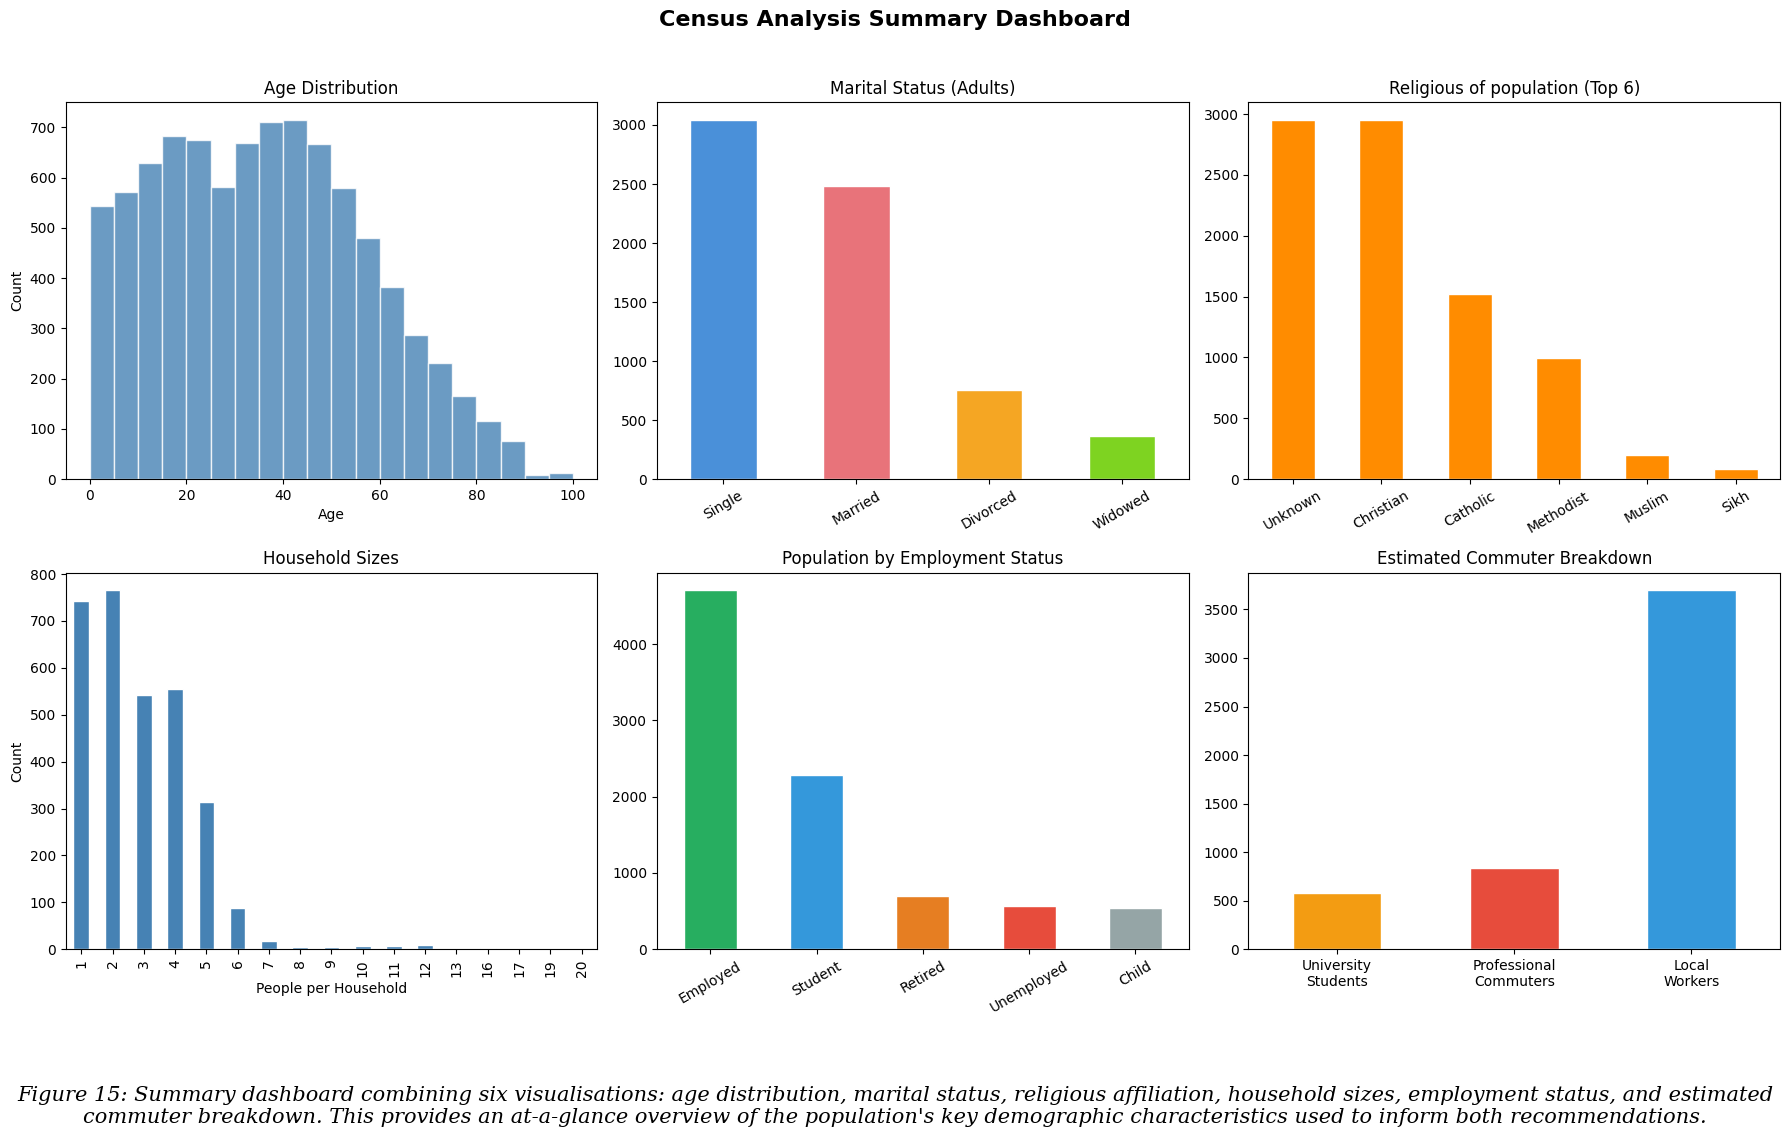

In [152]:

# Create a summary dashboard with key metrics
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Census Analysis Summary Dashboard', fontsize=16, fontweight='bold', y=1.02)

# 1. Age distribution
axes[0, 0].hist(df['Age'], bins=range(0, 105, 5), edgecolor='white', alpha=0.8, color='steelblue')
axes[0, 0].set_title('Age Distribution')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Count')

# 2. Marital status (adults)
marital_counts.plot(kind='bar', ax=axes[0, 1], color=['#4A90D9', '#E8737A', '#F5A623', '#7ED321'], edgecolor='white')
axes[0, 1].set_title('Marital Status (Adults)')
axes[0, 1].set_xlabel('')
plt.sca(axes[0, 1])
plt.xticks(rotation=30)

# 3. Religion
religion_counts = df['Religion'].value_counts()
religion_count = religion_counts[religion_counts.index]
religion_count.head(6).plot(kind='bar', ax=axes[0, 2], color='darkorange', edgecolor='white')
axes[0, 2].set_title('Religious of population (Top 6)')
axes[0, 2].set_xlabel('')
plt.sca(axes[0, 2])
plt.xticks(rotation=30)

# 4. Household sizes
household_sizes.value_counts().sort_index().plot(kind='bar', ax=axes[1, 0], color='steelblue', edgecolor='white')
axes[1, 0].set_title('Household Sizes')
axes[1, 0].set_xlabel('People per Household')
axes[1, 0].set_ylabel('Count')

# 5. Employment breakdown
employment_cats = {
    'Employed': len(df[~df['Is_Child'] & ~df['Is_Student'] & ~df['Is_Unemployed'] & ~df['Is_Retired'] & (df['Occupation'] != 'Child')]),
    'Student': df['Is_Student'].sum(),
    'Retired': df['Is_Retired'].sum(),
    'Unemployed': df['Is_Unemployed'].sum(),
    'Child': df['Is_Child'].sum()
}
pd.Series(employment_cats).plot(kind='bar', ax=axes[1, 1], 
    color=['#27AE60', '#3498DB', '#E67E22', '#E74C3C', '#95A5A6'], edgecolor='white')
axes[1, 1].set_title('Population by Employment Status')
axes[1, 1].set_xlabel('')
plt.sca(axes[1, 1])
plt.xticks(rotation=30)

# Commuter estimate
commuter_data = {
    'University\nStudents': len(uni_students),
    'Professional\nCommuters': commuter_count - len(uni_students),
    'Local\nWorkers': len(df[(df['Age'] >= 18) & (df['Age'] < 65) & ~df['Is_Student'] & ~df['Is_Unemployed'] & ~df['Is_Retired']]) - (commuter_count - len(uni_students))
}
pd.Series(commuter_data).plot(kind='bar', ax=axes[1, 2], color=['#F39C12', '#E74C3C', '#3498DB'], edgecolor='white')
axes[1, 2].set_title('Estimated Commuter Breakdown')
axes[1, 2].set_xlabel('')
plt.sca(axes[1, 2])
plt.xticks(rotation=0)
plt.figtext(0.5, -0.09, 'Figure 15: Summary dashboard combining six visualisations: age distribution, marital status, religious affiliation, household sizes, employment status, and estimated commuter breakdown. This provides an at-a-glance overview of the population\'s key demographic characteristics used to inform both recommendations.', 
            ha='center', fontsize=15, fontname='Times New Roman', fontfamily='serif', style='italic', wrap=True)
plt.tight_layout()
plt.savefig('summary_dashboard1.png', dpi=150, bbox_inches='tight')
plt.show()